# **Capstone project: Providing data-driven suggestions for HR**

## Description and deliverables

This capstone project is an opportunity for you to analyze a dataset and build predictive models that can provide insights to the Human Resources (HR) department of a large consulting firm.

Upon completion, you will have two artifacts that you will be able to present to future employers. One is a brief one-page summary of this project that you will present to external stakeholders as the data professional in Salifort Motors. The other is a complete code notebook provided here. Based on your prior coursework, select one method to complete this project: use either a regression model or a machine learning model to predict whether an employee will leave the company. The exemplar following this actiivty shows both approaches, but you only need to do one.

In your deliverables, you will include the model evaluation (and interpretation if applicable), a data visualization(s) of your choice that is directly related to the question you ask, ethical considerations, and the resources you used to troubleshoot and find answers or solutions.


# **PACE stages**


<img src="../Image/Pace.png" width="220" height="220"/>


<img src="../Image/Plan.png" width="100" height="100" align="left"/>

## **Pace: Plan**

Consider the questions in your PACE Strategy Document to reflect on the Plan stage.

In this stage, consider the following:

### Understand the business scenario and problem

The HR department at Salifort Motors wants to take some initiatives to improve employee satisfaction levels at the company. They collected data from employees, but now they don’t know what to do with it. They refer to you as a data analytics professional and ask you to provide data-driven suggestions based on your understanding of the data. They have the following question: what’s likely to make the employee leave the company?

Your goals in this project are to analyze the data collected by the HR department and to build a model that predicts whether or not an employee will leave the company.

If you can predict employees likely to quit, it might be possible to identify factors that contribute to their leaving. Because it is time-consuming and expensive to find, interview, and hire new employees, increasing employee retention will be beneficial to the company.

### Familiarize yourself with the HR dataset

The dataset that you'll be using in this lab contains 15,000 rows and 10 columns for the variables listed below.

**Note:** you don't need to download any data to complete this lab. For more information about the data, refer to its source on [Kaggle](https://www.kaggle.com/datasets/mfaisalqureshi/hr-analytics-and-job-prediction?select=HR_comma_sep.csv).

Variable  |Description |
-----|-----|
satisfaction_level|Employee-reported job satisfaction level [0&ndash;1]|
last_evaluation|Score of employee's last performance review [0&ndash;1]|
number_project|Number of projects employee contributes to|
average_monthly_hours|Average number of hours employee worked per month|
time_spend_company|How long the employee has been with the company (years)
Work_accident|Whether or not the employee experienced an accident while at work
left|Whether or not the employee left the company
promotion_last_5years|Whether or not the employee was promoted in the last 5 years
Department|The employee's department
salary|The employee's salary (U.S. dollars)

💭
### Reflect on these questions as you complete the plan stage.

*  Who are your stakeholders for this project?
- What are you trying to solve or accomplish?
- What are your initial observations when you explore the data?
- What resources do you find yourself using as you complete this stage? (Make sure to include the links.)
- Do you have any ethical considerations in this stage?




- As partes interessadas deste projeto são a liderança sênior da empresa e a equipe de Recursos Humanos (RH), que utilizarão os resultados da análise para apoiar a tomada de decisões relacionadas à retenção de funcionários.
- O objetivo é desenvolver um modelo preditivo capaz de estimar a probabilidade de um funcionário deixar a empresa, ajudando a identificar fatores associados à rotatividade.
- Inicialmente, observei que o conjunto de dados contém informações sobre características dos funcionários, desempenho, satisfação no trabalho e status de desligamento.
- Documento de estratégia PACE (fornecido pelo curso). Documentação oficial das bibliotecas Python utilizadas na análise: Pandas: https://pandas.pydata.org/docs/ | NumPy: https://numpy.org/doc/ | SciPy: https://docs.scipy.org/doc/scipy/ | Matplotlib: https://matplotlib.org/stable/ | Seaborn: https://seaborn.pydata.org/ | Scikit-learn: https://scikit-learn.org/stable/ | XGBoost: https://xgboost.readthedocs.io/
- É importante garantir a privacidade e a confidencialidade dos dados dos funcionários e evitar vieses no desenvolvimento do modelo.


### ✍️ Registro da etapa Plan

- **Problema de negócio:** identificar funcionários com maior probabilidade de deixar a Salifort, para apoiar ações de retenção e reduzir os custos de recrutamento e treinamento.
- **Público interessado:** liderança sênior e equipe de Recursos Humanos.
- **Variável-alvo:** `left`. `left = 1` indica que o funcionário saiu da empresa; `left = 0` indica que permaneceu. O conjunto não distingue pedido de demissão de demissão, e ambos entram como saída.
- **Critério de sucesso:** a acurácia sozinha é enganosa em dados desbalanceados (cerca de 83% dos funcionários permaneceram). Por isso avaliamos recall, precision, F1-score e ROC-AUC da classe `left = 1`.
- **Limitações iniciais:** o conjunto não traz motivos de saída nem a data em que a satisfação foi medida, o que impede confirmar se a satisfação é anterior à decisão de sair.


## Step 1. Imports

*   Import packages
*   Load dataset



### Import packages

In [1]:
# Import packages
import os
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")

import pandas as pd
import numpy as np
from scipy import stats

import seaborn as sns
import matplotlib.pyplot as plt

# For data modeling
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# For metrics and helpful functions
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report,
    roc_auc_score, roc_curve, precision_recall_curve
)
from sklearn.tree import plot_tree


### Load dataset

`Pandas` is used to read a dataset called **`HR_capstone_dataset.csv`.**  As shown in this cell, the dataset has been automatically loaded in for you. You do not need to download the .csv file, or provide more code, in order to access the dataset and proceed with this lab. Please continue with this activity by completing the following instructions.

In [2]:
# RUN THIS CELL TO IMPORT YOUR DATA.

# Load dataset into a dataframe (aceita a estrutura em pastas do repositório ou o nome original)
caminhos_possiveis = [
    "../Data/HR_capstone_dataset.csv",
    "Data/HR_capstone_dataset.csv",
    "HR_capstone_dataset.csv",
    "HR_capstone_dataset__1_.csv",
]
caminho = next((p for p in caminhos_possiveis if os.path.exists(p)), caminhos_possiveis[0])
df0 = pd.read_csv(caminho)

# Display first few rows of the dataframe
df0.head()


,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,Department,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low


In [3]:
df0.shape

(14999, 10)

In [4]:
df0.dtypes

satisfaction_level       float64
last_evaluation          float64
number_project             int64
average_montly_hours       int64
time_spend_company         int64
Work_accident              int64
left                       int64
promotion_last_5years      int64
Department                   str
salary                       str
dtype: object

## Step 2. Data Exploration (Initial EDA and data cleaning)

- Understand your variables
- Clean your dataset (missing data, redundant data, outliers)



### Gather basic information about the data

In [5]:
# Gather basic information about the data
df0.info()


<class 'pandas.DataFrame'>
RangeIndex: 14999 entries, 0 to 14998
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   satisfaction_level     14999 non-null  float64
 1   last_evaluation        14999 non-null  float64
 2   number_project         14999 non-null  int64  
 3   average_montly_hours   14999 non-null  int64  
 4   time_spend_company     14999 non-null  int64  
 5   Work_accident          14999 non-null  int64  
 6   left                   14999 non-null  int64  
 7   promotion_last_5years  14999 non-null  int64  
 8   Department             14999 non-null  str    
 9   salary                 14999 non-null  str    
dtypes: float64(2), int64(6), str(2)
memory usage: 1.3 MB


### Gather descriptive statistics about the data

In [6]:
# Gather descriptive statistics about the data
df0.describe()


,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years
count,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000
mean,0.612834,0.716102,3.803054,201.050337,3.498233,0.144610,0.238083,0.021268
std,0.248631,0.171169,1.232592,49.943099,1.460136,0.351719,0.425924,0.144281
min,0.090000,0.360000,2.000000,96.000000,2.000000,0.000000,0.000000,0.000000
25%,0.440000,0.560000,3.000000,156.000000,3.000000,0.000000,0.000000,0.000000
50%,0.640000,0.720000,4.000000,200.000000,3.000000,0.000000,0.000000,0.000000
75%,0.820000,0.870000,5.000000,245.000000,4.000000,0.000000,0.000000,0.000000
max,1.000000,1.000000,7.000000,310.000000,10.000000,1.000000,1.000000,1.000000


### Rename columns

As a data cleaning step, rename the columns as needed. Standardize the column names so that they are all in `snake_case`, correct any column names that are misspelled, and make column names more concise as needed.

In [7]:
# Display all column names
df0.columns


Index(['satisfaction_level', 'last_evaluation', 'number_project',
       'average_montly_hours', 'time_spend_company', 'Work_accident', 'left',
       'promotion_last_5years', 'Department', 'salary'],
      dtype='str')

In [8]:
# Rename columns as needed
df0 = df0.rename(
    columns={
        "average_montly_hours": "average_monthly_hours",
        "time_spend_company": "tenure",
        "Work_accident": "work_accident",
        "Department": "department",
        "number_project": "number_projects",
        "promotion_last_5years": "promotion_last_5_years"
    }
)

# Display all column names after the update
df0.columns

Index(['satisfaction_level', 'last_evaluation', 'number_projects',
       'average_monthly_hours', 'tenure', 'work_accident', 'left',
       'promotion_last_5_years', 'department', 'salary'],
      dtype='str')

### Check missing values

Check for any missing values in the data.

In [9]:
# Check for missing values
df0.isna().sum()


satisfaction_level        0
last_evaluation           0
number_projects           0
average_monthly_hours     0
tenure                    0
work_accident             0
left                      0
promotion_last_5_years    0
department                0
salary                    0
dtype: int64

### Check duplicates

Check for any duplicate entries in the data.

In [10]:
# Check for duplicates
df0.duplicated().sum()


np.int64(3008)

In [11]:
# Inspect some rows containing duplicates as needed
df0[df0.duplicated(keep=False)].sort_values(by=df0.columns.tolist())

,satisfaction_level,last_evaluation,number_projects,average_monthly_hours,tenure,work_accident,left,promotion_last_5_years,department,salary
30,0.09,0.62,6,294,4,0,1,0,accounting,low
12030,0.09,0.62,6,294,4,0,1,0,accounting,low
14241,0.09,0.62,6,294,4,0,1,0,accounting,low
71,0.09,0.77,5,275,4,0,1,0,product_mng,medium
12071,0.09,0.77,5,275,4,0,1,0,product_mng,medium
...,...,...,...,...,...,...,...,...,...,...
13089,1.00,0.88,6,201,4,0,0,0,technical,low
11375,1.00,0.93,5,167,3,0,0,0,sales,medium
13586,1.00,0.93,5,167,3,0,0,0,sales,medium
10691,1.00,0.93,5,231,2,0,0,0,marketing,medium


In [12]:
# Drop duplicates and save resulting dataframe in a new variable as needed
df_clean = df0.drop_duplicates(keep='first')


# Display first few rows of new dataframe as needed
df_clean.head()


,satisfaction_level,last_evaluation,number_projects,average_monthly_hours,tenure,work_accident,left,promotion_last_5_years,department,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low


### Check outliers

Check for outliers in the data.

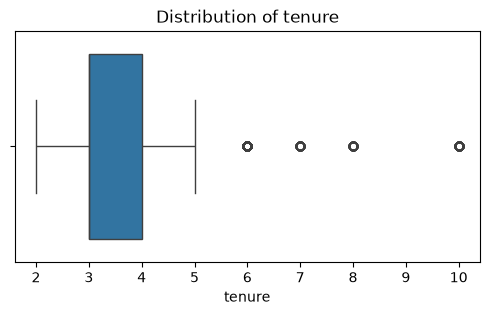

In [13]:
# Create a boxplot to visualize distribution of `time_spend_company` and detect any outliers
fig, ax = plt.subplots(figsize=(6, 3))

sns.boxplot(x=df_clean['tenure'], ax=ax)
ax.set_title('Distribution of tenure')
plt.show()


In [14]:
# Determine the number of rows containing outliers

Q1 = df_clean['tenure'].quantile(0.25)
Q3 = df_clean['tenure'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)

outliers = df_clean[
    (df_clean['tenure'] < lower_limit) |
    (df_clean['tenure'] > upper_limit)
]

print("Outliers:", len(outliers))


Lower limit: 1.5
Upper limit: 5.5
Outliers: 824


Certain types of models are more sensitive to outliers than others. When you get to the stage of building your model, consider whether to remove outliers, based on the type of model you decide to use.

<img src="../Image/Analyze.png" width="100" height="100" align="left"/>

# pAce: Analyze Stage
- Perform EDA (analyze relationships between variables)


💭
### Reflect on these questions as you complete the analyze stage.

- What did you observe about the relationships between variables?
- What do you observe about the distributions in the data?
- What transformations did you make with your data? Why did you chose to make those decisions?
- What are some purposes of EDA before constructing a predictive model?
- What resources do you find yourself using as you complete this stage? (Make sure to include the links.)
- Do you have any ethical considerations in this stage?




- fatores como nível de satisfação, tempo de permanência na empresa (tenure), número de projetos e média de horas trabalhadas por mês parecem estar relacionados à saída dos funcionários.
- variáveis numéricas apresentaram distribuições variadas. O nível de satisfação apresentou valores distribuídos entre 0,09 e 1,00, enquanto o tempo de permanência na empresa concentrou-se principalmente entre 2 e 5 anos.
- Padronização e correção dos nomes das colunas para o formato snake_case.
Correção de erros de nomenclatura, como average_montly_hours para average_monthly_hours.
Remoção de 3.008 registros duplicados para evitar vieses na análise e no treinamento do modelo.
- Compreender a estrutura e a qualidade dos dados.
Identificar valores ausentes, duplicados e outliers.
Explorar relações entre variáveis.
Detectar padrões e tendências que possam ajudar na modelagem.
- Documento de Estratégia PACE (fornecido pelo curso); Materiais disponibilizados (vídeos e atividades do curso);
Documentação do Pandas: https://pandas.pydata.org/docs/
Documentação do NumPy: https://numpy.org/doc/
Documentação do Matplotlib: https://matplotlib.org/stable/
Documentação do Seaborn: https://seaborn.pydata.org/
Documentação do Scikit-learn: https://scikit-learn.org/stable/
- proteger a privacidade dos funcionários e garantir a confidencialidade dos dados analisados.

## Step 2. Data Exploration (Continue EDA)

Begin by understanding how many employees left and what percentage of all employees this figure represents.

In [15]:
# Get numbers of people who left vs. stayed
df_clean['left'].value_counts()

left
0    10000
1     1991
Name: count, dtype: int64

In [16]:
# Get percentages of people who left vs. stayed
left_percent = df_clean['left'].value_counts(normalize=True)

print(left_percent)

left
0    0.833959
1    0.166041
Name: proportion, dtype: float64


### Data visualizations

Now, examine variables that you're interested in, and create plots to visualize relationships between variables in the data.

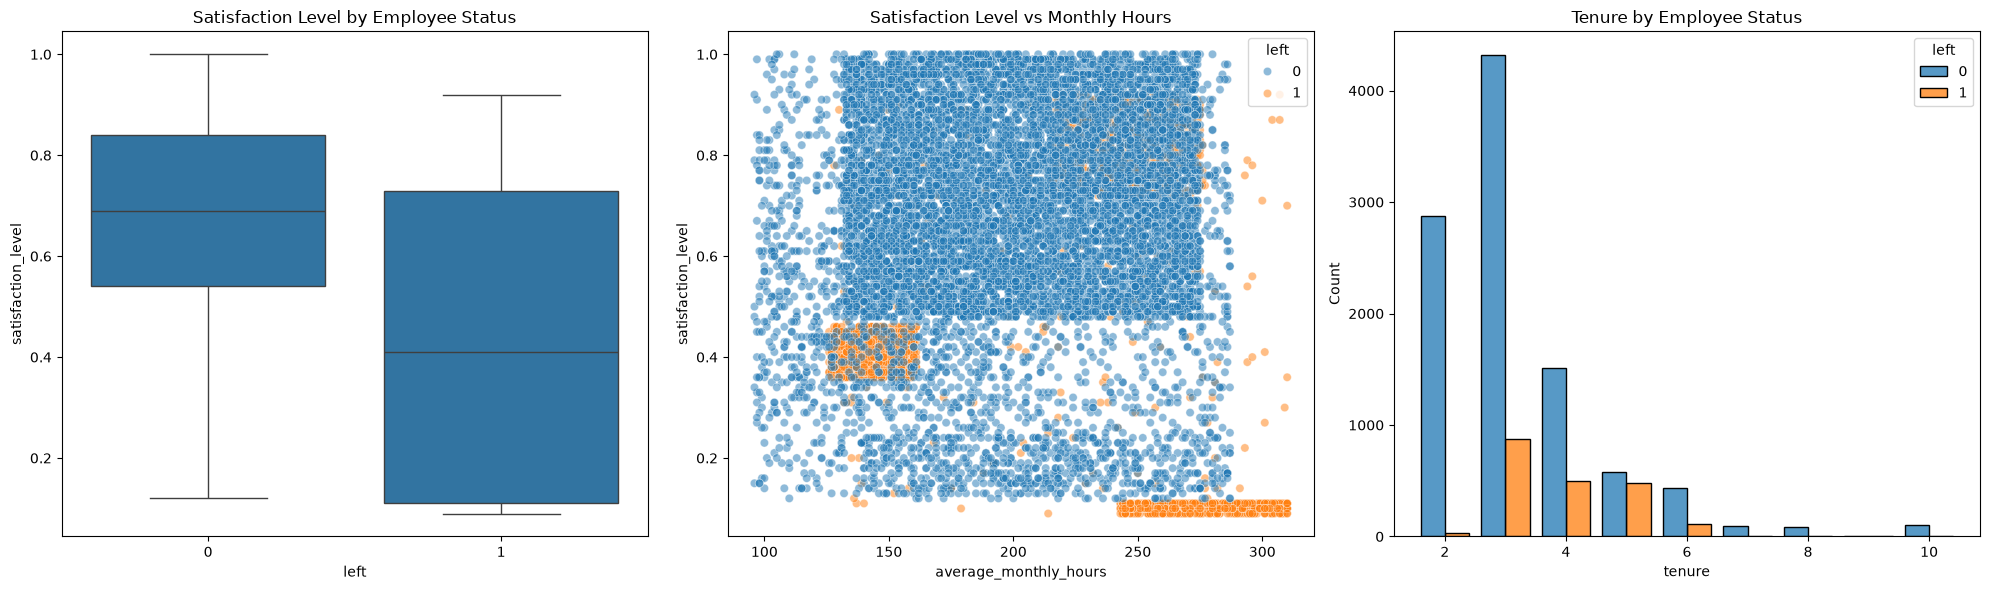

In [17]:
# Create a plot as needed
fig, ax = plt.subplots(1, 3, figsize=(20, 6))

# Gráfico 1: Satisfação por status do funcionário
sns.boxplot(
    data=df_clean,
    x='left',
    y='satisfaction_level',
    ax=ax[0]
)
ax[0].set_title('Satisfaction Level by Employee Status')

# Gráfico 2: Satisfação vs horas trabalhadas
sns.scatterplot(
    data=df_clean,
    x='average_monthly_hours',
    y='satisfaction_level',
    hue='left',
    alpha=0.5,
    ax=ax[1]
)
ax[1].set_title('Satisfaction Level vs Monthly Hours')

# Gráfico 3: Tempo de empresa por status
sns.histplot(
    data=df_clean,
    x='tenure',
    hue='left',
    multiple='dodge',
    discrete=True,
    shrink=0.8,
    ax=ax[2]
)
ax[2].set_title('Tenure by Employee Status')

plt.tight_layout()
plt.show()

In [18]:
df_clean.groupby(['left'])['satisfaction_level'].agg(['mean', 'median'])

,mean,median
left,,
0,0.667365,0.69
1,0.440271,0.41


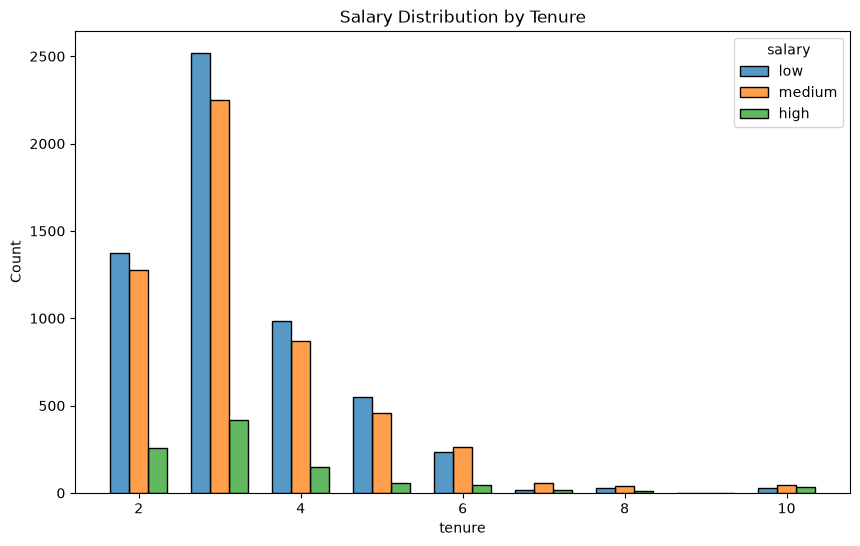

In [19]:
plt.figure(figsize=(10,6))

sns.histplot(
    data=df_clean,
    x='tenure',
    hue='salary',
    multiple='dodge',
    discrete=True,
    shrink=0.7
)

plt.title('Salary Distribution by Tenure')
plt.show()

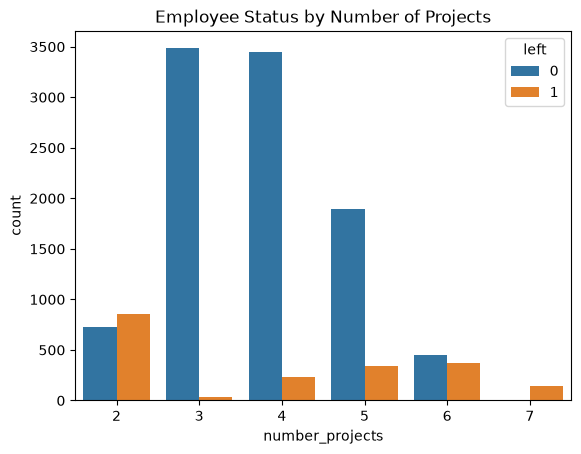

In [20]:
# Create a plot as needed
sns.countplot(x='number_projects', hue='left', data=df_clean)
plt.title('Employee Status by Number of Projects')
plt.show()

Quem tem 2 projetos saiu em 54% dos casos, e quem tem 6 projetos em 45%. Com 7 projetos, todos os 145 casos saíram. Já quem tem 3 projetos saiu em apenas 1,1% dos casos, e quem tem 4, em 6,4%. O padrão em U sugere que a pouca carga (possível subutilização) e a carga muito alta (possível sobrecarga) estão associadas à saída.


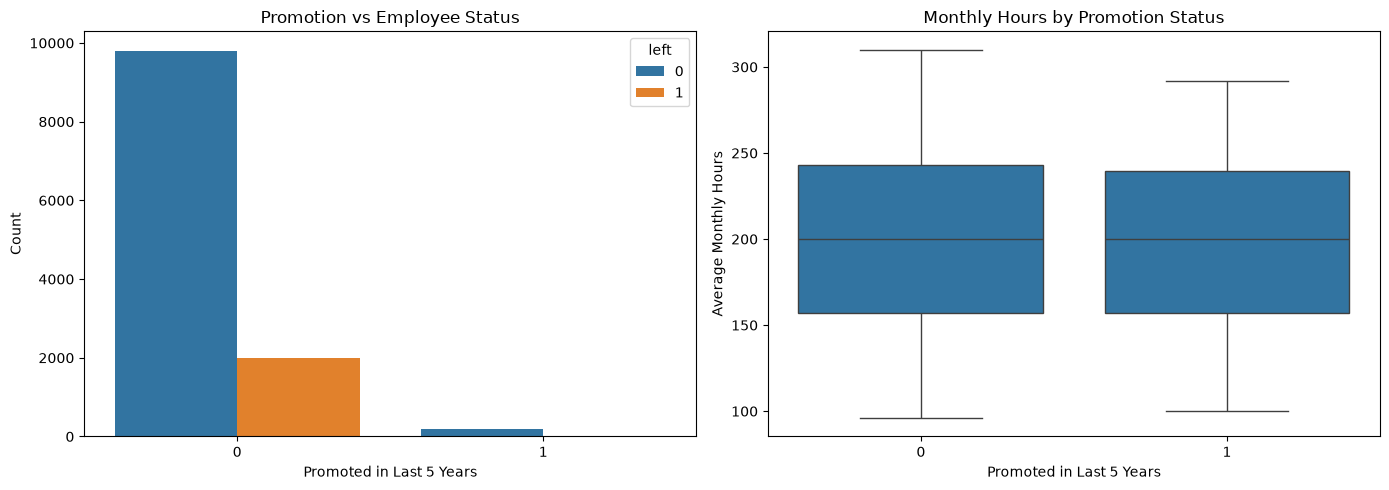

In [21]:
# Create a plot as needed
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: Promoção vs Status do Funcionário
sns.countplot(
    data=df_clean,
    x='promotion_last_5_years',
    hue='left',
    ax=ax[0]
)

ax[0].set_title('Promotion vs Employee Status')
ax[0].set_xlabel('Promoted in Last 5 Years')
ax[0].set_ylabel('Count')

# Gráfico 2: Horas Mensais por Status de Promoção
sns.boxplot(
    data=df_clean,
    x='promotion_last_5_years',
    y='average_monthly_hours',
    ax=ax[1]
)

ax[1].set_title('Monthly Hours by Promotion Status')
ax[1].set_xlabel('Promoted in Last 5 Years')
ax[1].set_ylabel('Average Monthly Hours')

plt.tight_layout()
plt.show()


Apenas 203 funcionários foram promovidos nos últimos 5 anos. Entre eles, 3,9% saíram, contra 16,8% dos não promovidos. A promoção aparece associada à permanência, mas a amostra de promovidos é pequena e a relação pode ser indireta, já que quem é promovido tende a ter melhor desempenho.


In [22]:
df_clean["department"].value_counts()

department
sales          3239
technical      2244
support        1821
IT              976
RandD           694
product_mng     686
marketing       673
accounting      621
hr              601
management      436
Name: count, dtype: int64

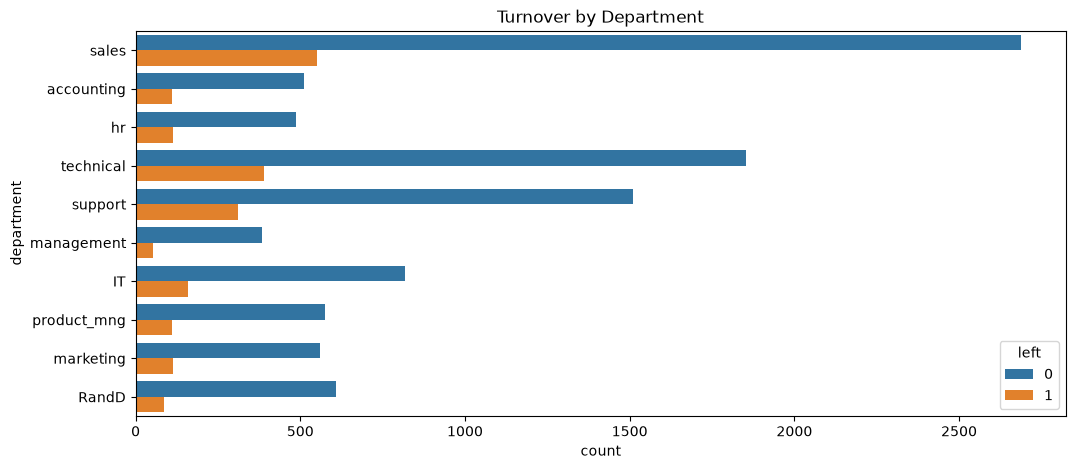

In [23]:
# Create a plot as needed
plt.figure(figsize=(12,5))
sns.countplot(y='department', hue='left', data=df_clean)
plt.title('Turnover by Department')
plt.show()


Taxa de saída por departamento: as diferenças são pequenas. RandD (12,2%) e management (11,9%) têm as menores taxas; hr (18,8%) e accounting (17,6%), as maiores. Como o contraste é pequeno, o departamento provavelmente não é o principal fator de saída.


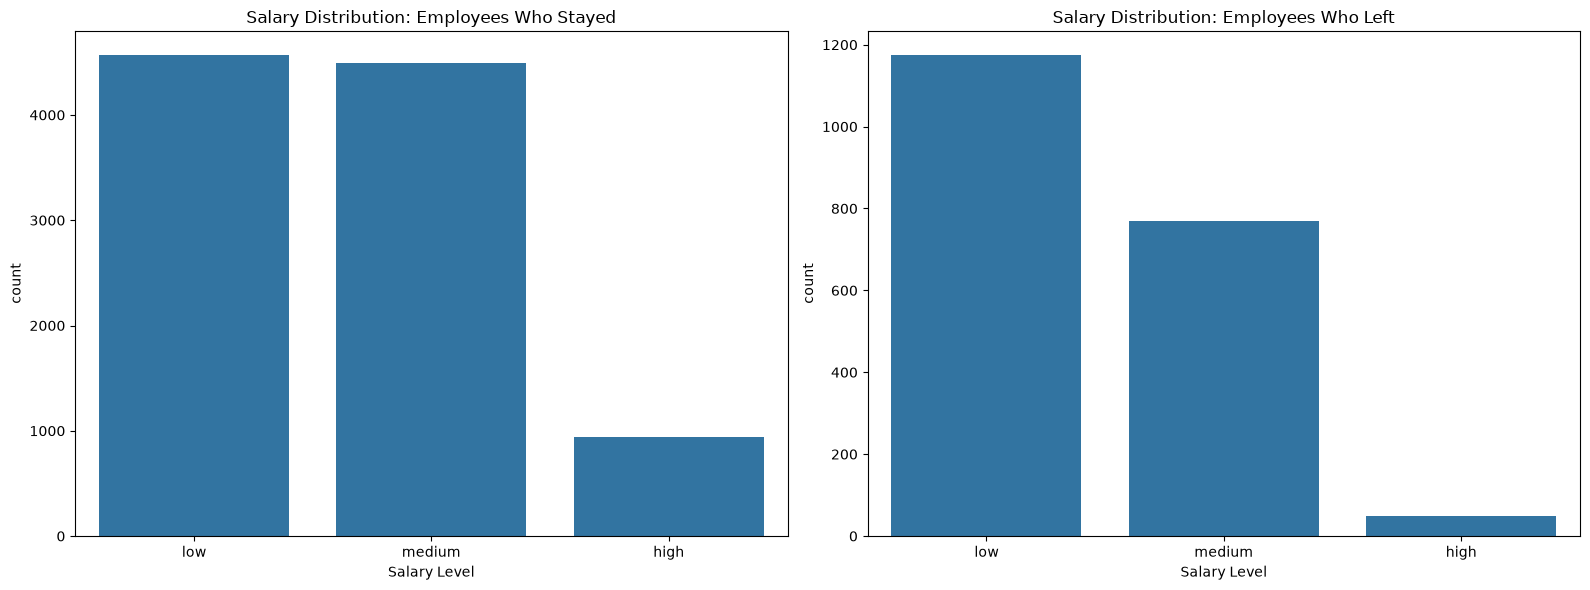

In [24]:
# Create a plot as needed
fig, ax = plt.subplots(1, 2, figsize=(16, 6))

# Funcionários que permaneceram
stayed = df_clean[df_clean['left'] == 0]

sns.countplot(
    data=stayed,
    x='salary',
    order=['low', 'medium', 'high'],
    ax=ax[0]
)

ax[0].set_title('Salary Distribution: Employees Who Stayed')
ax[0].set_xlabel('Salary Level')

# Funcionários que saíram
left = df_clean[df_clean['left'] == 1]

sns.countplot(
    data=left,
    x='salary',
    order=['low', 'medium', 'high'],
    ax=ax[1]
)

ax[1].set_title('Salary Distribution: Employees Who Left')
ax[1].set_xlabel('Salary Level')

plt.tight_layout()
plt.show()


Funcionários de salário baixo saíram em 20,5% dos casos, contra 14,6% no salário médio e 4,8% no alto. Há associação clara entre remuneração e retenção, mas o salário pode estar confundido com cargo e tempo de casa.


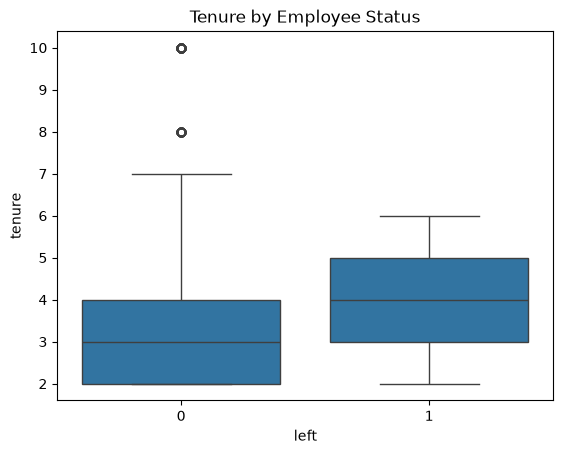

In [25]:
# Create a plot as needed
sns.boxplot(x='left', y='tenure', data=df_clean)
plt.title('Tenure by Employee Status')
plt.show()


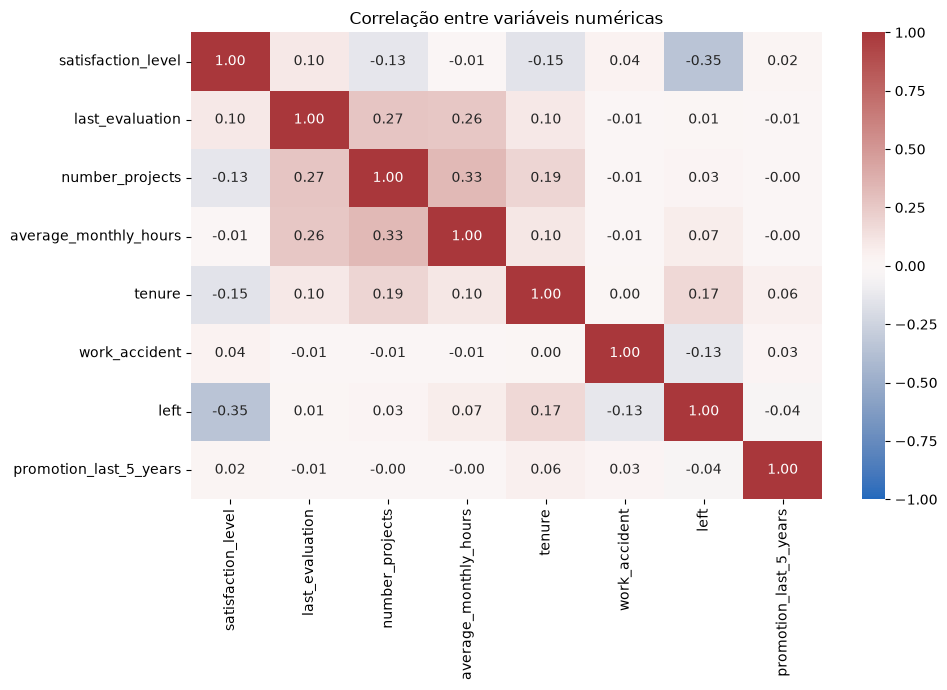

In [26]:
# Create a plot as needed
num_cols = df_clean.select_dtypes(include=np.number).columns

plt.figure(figsize=(10, 7))

sns.heatmap(
    df_clean[num_cols].corr(), vmin=-1, vmax=1, annot=True,
    cmap=sns.color_palette("vlag", as_cmap=True), fmt='.2f'
)
plt.title('Correlação entre variáveis numéricas')
plt.tight_layout()
plt.show()

Número de projetos, horas mensais e avaliação de desempenho têm correlação positiva entre si (de 0,26 a 0,33). A saída (`left`) tem correlação negativa com a satisfação (-0,35) e positiva com o tempo de casa (0,17). As demais variáveis numéricas têm correlação fraca com `left`, abaixo de 0,1 em módulo. Isso indica que algumas relações são não lineares, como o padrão em U do número de projetos, e que a correlação linear subestima essas variáveis.


### Testes de hipóteses estatísticas

Para validar se as diferenças observadas na EDA entre funcionários que permaneceram (`left = 0`) e os que saíram (`left = 1`) são estatisticamente significativas ao nível $\alpha = 0,05$, realizamos testes formais:

1. **Variáveis contínuas (`satisfaction_level` e `average_monthly_hours`)**:
   - $H_0$: Não há diferença significativa na distribuição/média da variável entre quem saiu e quem permaneceu.
   - $H_1$: Há diferença estatisticamente significativa entre os dois grupos.
   - *Método:* aplicamos o **teste $t$ de Welch** (`equal_var=False`, adequado para variâncias desiguais em grandes amostras) em conjunto com o **teste não paramétrico de Mann-Whitney $U$**, robusto à assimetria e à bimodalidade observada nas horas mensais.
2. **Variáveis categóricas (`promotion_last_5_years`, `salary` e `work_accident`)**:
   - $H_0$: O desligamento (`left`) é independente da variável categórica.
   - $H_1$: Existe associação estatisticamente significativa entre a variável e o desligamento.
   - *Método:* **teste Qui-quadrado de independência ($\chi^2$)**.


In [27]:
# Estatísticas descritivas comparativas por status de desligamento
resumo_grupos = (
    df_clean.groupby('left')[['satisfaction_level', 'average_monthly_hours']]
    .agg(['mean', 'std', 'median', lambda s: s.quantile(0.75) - s.quantile(0.25)])
    .rename(columns={'<lambda_0>': 'IQR'})
    .round(4)
)
print('Estatísticas comparativas (0 = permaneceu, 1 = saiu):')
display(resumo_grupos)

# 1. Testes para variáveis contínuas (Welch t-test e Mann-Whitney U)
ativos = df_clean[df_clean['left'] == 0]
desligados = df_clean[df_clean['left'] == 1]

testes_continuos = []
for col in ['satisfaction_level', 'average_monthly_hours']:
    t_stat, t_p = stats.ttest_ind(desligados[col], ativos[col], equal_var=False)
    u_stat, u_p = stats.mannwhitneyu(desligados[col], ativos[col], alternative='two-sided')
    testes_continuos.append({
        'Variável': col,
        'Média (Ficou)': round(ativos[col].mean(), 4),
        'Média (Saiu)': round(desligados[col].mean(), 4),
        'Mediana (Ficou)': round(ativos[col].median(), 4),
        'Mediana (Saiu)': round(desligados[col].median(), 4),
        'Estatística t (Welch)': round(t_stat, 4),
        'p-valor (Welch)': f'{t_p:.2e}',
        'p-valor (Mann-Whitney)': f'{u_p:.2e}',
        'Decisão (α=0.05)': 'Rejeita H0' if (t_p < 0.05 and u_p < 0.05) else 'Não rejeita H0'
    })

print('\nTestes de hipóteses — variáveis numéricas:')
display(pd.DataFrame(testes_continuos))

# 2. Testes Qui-quadrado para variáveis categóricas/binárias
testes_categoricos = []
for cat in ['promotion_last_5_years', 'salary', 'work_accident']:
    tabela = pd.crosstab(df_clean[cat], df_clean['left'])
    chi2, p_val, gl, _ = stats.chi2_contingency(tabela)
    testes_categoricos.append({
        'Variável': cat,
        'Qui-quadrado (χ²)': round(chi2, 4),
        'Graus de liberdade': gl,
        'p-valor': f'{p_val:.2e}',
        'Decisão (α=0.05)': 'Rejeita H0' if p_val < 0.05 else 'Não rejeita H0'
    })

print('\nTestes Qui-quadrado de independência — variáveis categóricas:')
display(pd.DataFrame(testes_categoricos))


Estatísticas comparativas (0 = permaneceu, 1 = saiu):


satisfaction_level                      average_monthly_hours           \
                   mean     std median   IQR                  mean      std   
left                                                                          
0                0.6674  0.2171   0.69  0.30              198.9427  45.6655   
1                0.4403  0.2652   0.41  0.62              208.1622  61.2951   

                    
     median    IQR  
left                
0     198.0   76.0  
1     226.0  116.5


Testes de hipóteses — variáveis numéricas:


,Variável,Média (Ficou),Média (Saiu),Mediana (Ficou),Mediana (Saiu),Estatística t (Welch),p-valor (Welch),p-valor (Mann-Whitney),Decisão (α=0.05)
0,satisfaction_level,0.6674,0.4403,0.69,0.41,-35.8893,1.19e-228,2.24e-266,Rejeita H0
1,average_monthly_hours,198.9427,208.1622,198.00,226.00,6.3688,2.27e-10,1.83e-07,Rejeita H0



Testes Qui-quadrado de independência — variáveis categóricas:


,Variável,Qui-quadrado (χ²),Graus de liberdade,p-valor,Decisão (α=0.05)
0,promotion_last_5_years,22.9921,1,1.63e-06,Rejeita H0
1,salary,175.2107,2,8.98e-39,Rejeita H0
2,work_accident,187.7378,1,9.91e-43,Rejeita H0


**Conclusão dos testes estatísticos:**
- Em todos os testes avaliados, obteve-se $p < 0,001$, rejeitando-se a hipótese nula ($H_0$) ao nível de significância de 5%.
- Para `satisfaction_level`, a diferença entre quem saiu (média `0,44`, mediana `0,41`) e quem ficou (média `0,67`, mediana `0,69`) é altamente expressiva ($t = -35,89$).
- Para `average_monthly_hours`, embora a diferença nas médias pareça moderada (`208,16 h` vs. `198,94 h`, $t = 6,37$), a **mediana** entre os desligados salta para **`226,0 h`** (contra `198,0 h` dos ativos) e o desvio-padrão é bem maior (`61,30 h` vs. `45,67 h`). Isso confirma estatisticamente o comportamento bimodal visto nos gráficos: coexistem um grupo que sai com subcarga (~130–160 h e 2 projetos) e outro que sai em sobrecarga (> 240 h e 6–7 projetos).
- As associações com `promotion_last_5_years` ($\chi^2 = 22,99$), `salary` ($\chi^2 = 175,21$) e `work_accident` ($\chi^2 = 187,74$) também são estatisticamente significativas, lembrando que significância estatística em amostras grandes não implica relação causal direta.


### Insights

- A satisfação é o sinal mais forte: média de 0,44 entre quem saiu e 0,67 entre quem ficou (correlação de -0,35 com `left`).
- Promoção nos últimos 5 anos está associada à permanência: saída de 3,9% entre os promovidos e 16,8% entre os não promovidos.
- Quem saiu tem mediana de 4 anos de casa, contra 3 de quem ficou. O salário baixo concentra mais saídas (20,5%) que o alto (4,8%).
- O número de projetos tem padrão em U: 2 projetos (54% de saída) e 6 ou mais (45% a 100%), contra 3 projetos (1,1%).
- Quem sofreu acidente de trabalho saiu menos (5,7%, contra 18,6%). Resultado contraintuitivo, a verificar.


### ✍️ Registro da etapa Analyze — evidências da EDA

Registro com os valores obtidos nas células acima, após remover os 3.008 duplicados (11.991 registros).

- **Distribuição da variável-alvo:** 16,6% saíram (1.991) e 83,4% permaneceram (10.000). Desbalanceamento moderado, por isso a acurácia isolada não basta.
- **Satisfação e desligamento:** média de 0,44 entre quem saiu e 0,67 entre quem ficou. A correlação com `left` é de -0,35, a mais forte entre as variáveis numéricas.
- **Carga de trabalho e número de projetos:** a taxa de saída por número de projetos segue um padrão em U: 2 projetos (54%), 3 (1,1%), 4 (6,4%), 5 (15,4%), 6 (44,9%) e 7 (100%, com 145 casos). Horas médias mensais: 208,2 h (mediana 226 h) entre quem saiu e 198,9 h (mediana 198 h) entre quem ficou.
- **Validação estatística (testes de hipóteses):** os testes $t$ de Welch e Mann-Whitney $U$ confirmaram diferenças significativas ($p < 0,001$) em satisfação e horas mensais, e o teste Qui-quadrado confirmou associação significativa ($p < 0,001$) para promoção, salário e acidente de trabalho.
- **Tempo de empresa, salário e promoção:** mediana de 4 anos de casa entre quem saiu e 3 entre quem ficou. Saída de 20,5% no salário baixo, 14,6% no médio e 4,8% no alto. Entre os promovidos nos últimos 5 anos, a saída foi de 3,9%, contra 16,8% dos não promovidos (apenas 203 promovidos).
- **Acidentes de trabalho:** quem sofreu acidente saiu em 5,7% dos casos, contra 18,6% de quem não sofreu. O resultado é contraintuitivo e merece verificação na origem dos dados.
- **Departamento:** diferenças pequenas, entre 11,9% (management) e 18,8% (hr).
- **Qualidade dos dados:** 3.008 duplicados removidos (cerca de 20% das linhas). Em `tenure`, 824 registros ficaram fora dos limites de 1,5 e 5,5 anos; desses, 109 eram saídas (13,2%).
- **Limitações:** associação não é causalidade. A satisfação pode ter sido medida depois da decisão de sair.


<img src="../Image/Construct.png" width="100" height="100" align="left"/>

# paCe: Construct Stage
- Determine which models are most appropriate
- Construct the model
- Confirm model assumptions
- Evaluate model results to determine how well your model fits the data


🔎
## Recall model assumptions

**Logistic Regression model assumptions**
- Outcome variable is categorical
- Observations are independent of each other
- No severe multicollinearity among X variables
- No extreme outliers
- Linear relationship between each X variable and the logit of the outcome variable
- Sufficiently large sample size





💭
### Reflect on these questions as you complete the constructing stage.

- Do you notice anything odd?
- Which independent variables did you choose for the model and why?
- Are each of the assumptions met?
- How well does your model fit the data?
- Can you improve it? Is there anything you would change about the model?
- What resources do you find yourself using as you complete this stage? (Make sure to include the links.)
- Do you have any ethical considerations in this stage?



- Foram removidos 3.008 registros duplicados (cerca de 20% das linhas). Em `tenure`, 824 registros ficaram fora dos limites de 1,5 e 5,5 anos e foram retirados da base de modelagem.
- Variáveis escolhidas: `satisfaction_level`, `last_evaluation`, `number_projects`, `average_monthly_hours`, `tenure`, `work_accident`, `promotion_last_5_years`, `department` e `salary`, por poderem influenciar a permanência do funcionário.
- Pressupostos: a variável-alvo é binária, a amostra é grande (11.167 registros após a remoção de outliers) e os duplicados foram removidos. A multicolinearidade é verificada com VIF após o ajuste da regressão logística. A linearidade com o logit não foi testada formalmente, e as variáveis não foram padronizadas.


### ✍️ Registro da etapa Construct — decisões de modelagem

- **Alvo e preditores:** `left` é o alvo. Preditores: satisfação, última avaliação, número de projetos, horas mensais, tempo de casa, acidente de trabalho, promoção nos últimos 5 anos, departamento (dummies) e salário (codificado como 0, 1 e 2). O conjunto não traz a data de coleta da satisfação, por isso não é possível confirmar que ela é anterior à decisão de sair.
- **Preparação:** salário codificado de forma ordinal; departamento em variáveis dummy (`drop_first=True`); duplicados e outliers de tenure removidos; divisão 75/25 estratificada pela variável-alvo (`random_state=0`).
- **Modelos:** regressão logística como referência interpretável; Árvore de Decisão, Random Forest e **XGBoost** (*gradient boosting*) para capturar relações não lineares e interações complexas, como o padrão em U do número de projetos e a bimodalidade das horas mensais.
- **Validação:** GridSearchCV com validação cruzada de 5 folds no conjunto de treino, com ajuste de hiperparâmetros pelo ROC-AUC. O conjunto de teste não foi usado para escolher hiperparâmetros.
- **Riscos:** desbalanceamento (16,6% de saídas); possível vazamento pela satisfação; viés por departamento e cargo ainda não avaliado; limite de 175 horas no Modelo C é arbitrário.


## Step 3. Model Building, Step 4. Results and Evaluation
- Fit a model that predicts the outcome variable using two or more independent variables
- Check model assumptions
- Evaluate the model

### Identify the type of prediction task.

Classificação binária. O objetivo é prever se um funcionário vai deixar a empresa (left = 1) ou ficar na empresa (left = 0).

### Identify the types of models most appropriate for this task.

Como a variável alvo é binária, modelos de classificação são apropriados. A Regressão Logística é um modelo adequado porque prevê a probabilidade de um funcionário sair da empresa e fornece resultados interpretáveis. Outros modelos possíveis incluem Árvores de Decisão, Florestas Aleatórias e modelos de Gradient Boosting.

### Modeling I - Logistic Regression Model


Add as many cells as you need to conduct the modeling process.

### Logistic Regression

In [28]:
### YOUR CODE HERE ###

df_slm = df_clean.copy()

# Encode salary as ordinal numeric category
salary_map = {'low': 0, 'medium': 1, 'high': 2}
df_slm['salary'] = df_slm['salary'].map(salary_map)

# Verificar se a codificação não gerou valores ausentes
df_slm['salary'].isna().sum(), df_slm['salary'].value_counts(dropna=False)

(np.int64(0),
 salary
 0    5740
 1    5261
 2     990
 Name: count, dtype: int64)

In [29]:
# Dummy encode department
df_slm = pd.get_dummies(
    df_slm,
    columns=['department'],
    drop_first=True
)

# Display first rows

df_slm.head()

,satisfaction_level,last_evaluation,number_projects,average_monthly_hours,tenure,work_accident,left,promotion_last_5_years,salary,department_RandD,department_accounting,department_hr,department_management,department_marketing,department_product_mng,department_sales,department_support,department_technical
0,0.38,0.53,2,157,3,0,1,0,0,False,False,False,False,False,False,True,False,False
1,0.80,0.86,5,262,6,0,1,0,1,False,False,False,False,False,False,True,False,False
2,0.11,0.88,7,272,4,0,1,0,1,False,False,False,False,False,False,True,False,False
3,0.72,0.87,5,223,5,0,1,0,0,False,False,False,False,False,False,True,False,False
4,0.37,0.52,2,159,3,0,1,0,0,False,False,False,False,False,False,True,False,False


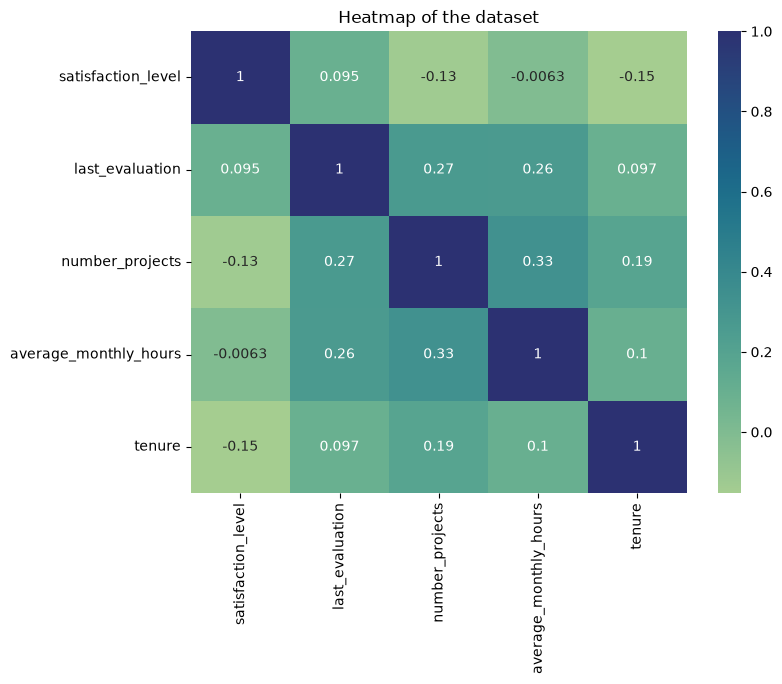

In [30]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    df_slm[
        ['satisfaction_level',
         'last_evaluation',
         'number_projects',
         'average_monthly_hours',
         'tenure']
    ].corr(),
    annot=True,
    cmap="crest"
)

plt.title('Heatmap of the dataset')
plt.show()

In [31]:
# Check class distribution

df_slm['left'].value_counts()

left
0    10000
1     1991
Name: count, dtype: int64

In [32]:
# Remover outliers de tenure da base de modelagem e documentar o impacto
df_model = df_slm[(df_slm['tenure'] >= lower_limit) & (df_slm['tenure'] <= upper_limit)].copy()

removidos = df_slm.shape[0] - df_model.shape[0]
saidas_removidas = df_slm['left'].sum() - df_model['left'].sum()
print(f"Registros removidos: {removidos}")
print(f"Saídas entre os removidos: {saidas_removidas} ({saidas_removidas / removidos:.1%})")
print(f"Taxa de saída antes: {df_slm['left'].mean():.1%} | depois: {df_model['left'].mean():.1%}")


Registros removidos: 824
Saídas entre os removidos: 109 (13.2%)
Taxa de saída antes: 16.6% | depois: 16.9%


**Justificativa e limitação:** a remoção reduziu a base em 824 registros, dos quais 109 eram saídas (13,2%), abaixo da média de 16,6%. Como os modelos A, B e C usam essa mesma base, funcionários com mais de 5,5 anos de casa ficam sem previsão. Árvores de decisão não são sensíveis a outliers, então a remoção é tecnicamente necessária apenas para a regressão logística. Recomenda-se testar as árvores com a base completa para verificar se o resultado se mantém.


In [33]:
# Define target variable
y = df_model['left']
y.head()

0    1
2    1
3    1
4    1
5    1
Name: left, dtype: int64

In [34]:
X = df_model.drop('left', axis=1)
X.head()

,satisfaction_level,last_evaluation,number_projects,average_monthly_hours,tenure,work_accident,promotion_last_5_years,salary,department_RandD,department_accounting,department_hr,department_management,department_marketing,department_product_mng,department_sales,department_support,department_technical
0,0.38,0.53,2,157,3,0,0,0,False,False,False,False,False,False,True,False,False
2,0.11,0.88,7,272,4,0,0,1,False,False,False,False,False,False,True,False,False
3,0.72,0.87,5,223,5,0,0,0,False,False,False,False,False,False,True,False,False
4,0.37,0.52,2,159,3,0,0,0,False,False,False,False,False,False,True,False,False
5,0.41,0.50,2,153,3,0,0,0,False,False,False,False,False,False,True,False,False


In [35]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=0, stratify=y
)

In [36]:

# Get shape of each training and testing set
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((8375, 17), (2792, 17), (8375,), (2792,))

In [37]:
log_clf = LogisticRegression(
    max_iter=1000,
    random_state=42
)

log_clf.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lb

In [38]:
# Generate predictions

y_pred = log_clf.predict(X_test)

In [39]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

Accuracy: 0.8255730659025788
Precision: 0.4666666666666667
Recall: 0.23779193205944799
F1 Score: 0.3150492264416315


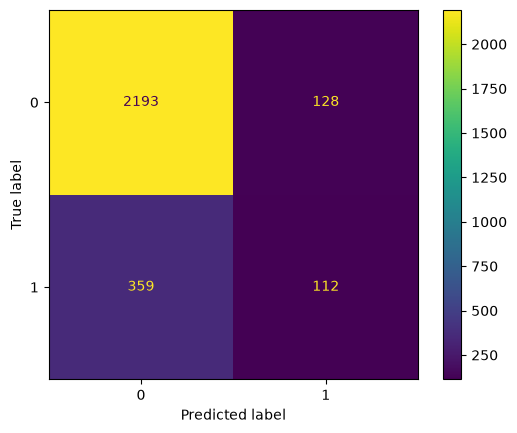

In [40]:
log_cm = confusion_matrix(y_test, y_pred, labels=log_clf.classes_)

# Create display of confusion matrix
log_disp = ConfusionMatrixDisplay(confusion_matrix=log_cm,
                                  display_labels=log_clf.classes_)

log_disp.plot(values_format='d')
plt.show()

**Observação**

 A matriz de confusão mostra que o modelo classifica corretamente
 a maioria dos funcionários que permanecem na empresa.
- Negativos verdadeiros: O número de pessoas que não saíram e que o modelo previu corretamente que não sairiam.

- Falsos positivos: O número de pessoas que não saíram e que o modelo previu incorretamente que sairiam.

- Falsos negativos: O número de pessoas que saíram e que o modelo previu incorretamente que não sairiam.

- Positivos verdadeiros: O número de pessoas que saíram e que o modelo previu corretamente que sairiam.

 No entanto, uma quantidade significativa de funcionários que
 realmente deixaram a empresa foi classificada incorretamente
 como permanentes, o que contribui para o baixo recall da classe 1.

In [41]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.86      0.94      0.90      2321
           1       0.47      0.24      0.32       471

    accuracy                           0.83      2792
   macro avg       0.66      0.59      0.61      2792
weighted avg       0.79      0.83      0.80      2792



**Observação**

 O modelo apresentou acurácia de aproximadamente 83%.
 Entretanto, o desempenho para identificar funcionários que saíram
 da empresa foi mais limitado, com recall de 24% e F1-score de 31%.
 Isso indica que muitos funcionários que realmente saíram não foram
 identificados corretamente pelo modelo.

 O desbalanceamento da variável alvo pode estar contribuindo para
 esse resultado.

In [42]:
df_slm['left'].value_counts(normalize=True)

left
0    0.833959
1    0.166041
Name: proportion, dtype: float64

**Observação:**

 A variável alvo apresenta desbalanceamento entre as classes.
 Aproximadamente 83% dos funcionários permaneceram na empresa,
 enquanto 17% deixaram a organização.

 Esse desbalanceamento pode explicar a alta acurácia do modelo e,
 ao mesmo tempo, o baixo desempenho na previsão dos funcionários
 que efetivamente saíram da empresa.

In [43]:
# Interpret model coefficients
coef_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': log_clf.coef_[0]
})

coef_df['Direção da associação'] = np.where(
    coef_df['Coefficient'] > 0, 'Maior chance prevista de saída',
    'Menor chance prevista de saída'
)
coef_df.reindex(
    coef_df['Coefficient'].abs().sort_values(ascending=False).index
)

,Feature,Coefficient,Direção da associação
0,satisfaction_level,-4.457911,Menor chance prevista de saída
5,work_accident,-1.473509,Menor chance prevista de saída
4,tenure,1.034527,Maior chance prevista de saída
6,promotion_last_5_years,-0.654135,Menor chance prevista de saída
7,salary,-0.506751,Menor chance prevista de saída
2,number_projects,-0.448934,Menor chance prevista de saída
8,department_RandD,-0.333275,Menor chance prevista de saída
9,department_accounting,-0.167258,Menor chance prevista de saída
11,department_management,-0.131064,Menor chance prevista de saída
10,department_hr,0.086519,Maior chance prevista de saída


**Observação:**

 A variável satisfaction_level apresentou o coeficiente negativo
 mais forte, indicando que níveis mais altos de satisfação estão
 associados a uma menor probabilidade de desligamento.

 A variável tenure apresentou o maior coeficiente positivo,
 sugerindo que funcionários com mais tempo de empresa possuem
 maior probabilidade de deixar a organização neste conjunto de dados.

 Promoções recentes, salários mais altos e histórico de acidente
 de trabalho também estão associados a uma menor probabilidade
 de saída, conforme indicado pelos coeficientes negativos.

#### Verificação de multicolinearidade (VIF)

Antes de confiar nos coeficientes, verificamos se os preditores são muito correlacionados entre si. Um VIF acima de 5 indica multicolinearidade que merece atenção e acima de 10 indica problema sério.


In [44]:
# VIF: para cada preditor, regride-o sobre os demais e calcula 1 / (1 - R²)
def calcular_vif(X_df):
    Xv = X_df.astype(float).values
    resultados = {}
    for i, coluna in enumerate(X_df.columns):
        outros = np.delete(Xv, i, axis=1)
        Xo = np.column_stack([np.ones(len(outros)), outros])
        beta, *_ = np.linalg.lstsq(Xo, Xv[:, i], rcond=None)
        residuo = Xv[:, i] - Xo @ beta
        r2 = 1 - (residuo @ residuo) / ((Xv[:, i] - Xv[:, i].mean()) ** 2).sum()
        resultados[coluna] = 1 / (1 - r2)
    return pd.Series(resultados).sort_values(ascending=False).round(2)

calcular_vif(X_train)


department_sales          3.12
department_technical      2.69
department_support        2.46
department_RandD          1.61
department_product_mng    1.60
department_marketing      1.59
department_hr             1.55
department_accounting     1.54
department_management     1.35
number_projects           1.26
average_monthly_hours     1.18
last_evaluation           1.16
tenure                    1.13
satisfaction_level        1.10
salary                    1.01
promotion_last_5_years    1.01
work_accident             1.00
dtype: float64

### Modeling II - Tree-Based Model

### Decision Tree

In [45]:
tree = DecisionTreeClassifier(
    random_state=42
)

In [46]:
cv_params = {
    'max_depth': [4, 6, 8, None],
    'min_samples_leaf': [1, 2, 5],
    'min_samples_split': [2, 4, 6]
}

scoring = [
    'accuracy',
    'precision',
    'recall',
    'f1',
    'roc_auc'
]

tree_cv = GridSearchCV(
    tree,
    cv_params,
    scoring=scoring,
    cv=5,
    refit='roc_auc',
    n_jobs=4
)

In [47]:
tree_cv.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [4, 6, ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 4, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","['accuracy', 'precision', ...]"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",4
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'roc_auc'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verb

In [48]:
tree_cv.best_score_

np.float64(0.9750741469209515)

In [49]:
tree_cv.best_params_

{'max_depth': 4, 'min_samples_leaf': 5, 'min_samples_split': 2}

In [50]:
tree_pred = tree_cv.best_estimator_.predict(X_test)

In [51]:
print(classification_report(y_test, tree_pred))

              precision    recall  f1-score   support

           0       0.99      0.99      0.99      2321
           1       0.96      0.93      0.94       471

    accuracy                           0.98      2792
   macro avg       0.97      0.96      0.97      2792
weighted avg       0.98      0.98      0.98      2792



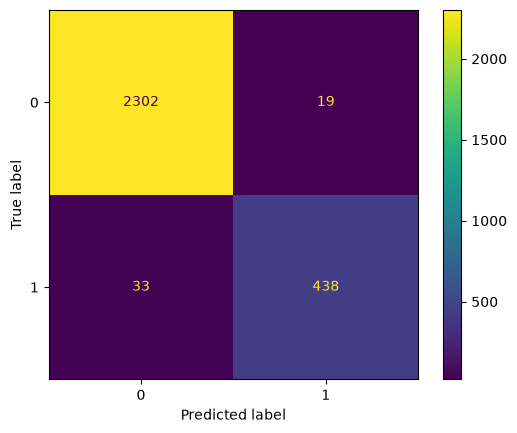

In [52]:
log_cm = confusion_matrix(y_test, tree_pred)

log_disp = ConfusionMatrixDisplay(confusion_matrix=log_cm, display_labels=tree_cv.classes_)

log_disp.plot()

plt.show()

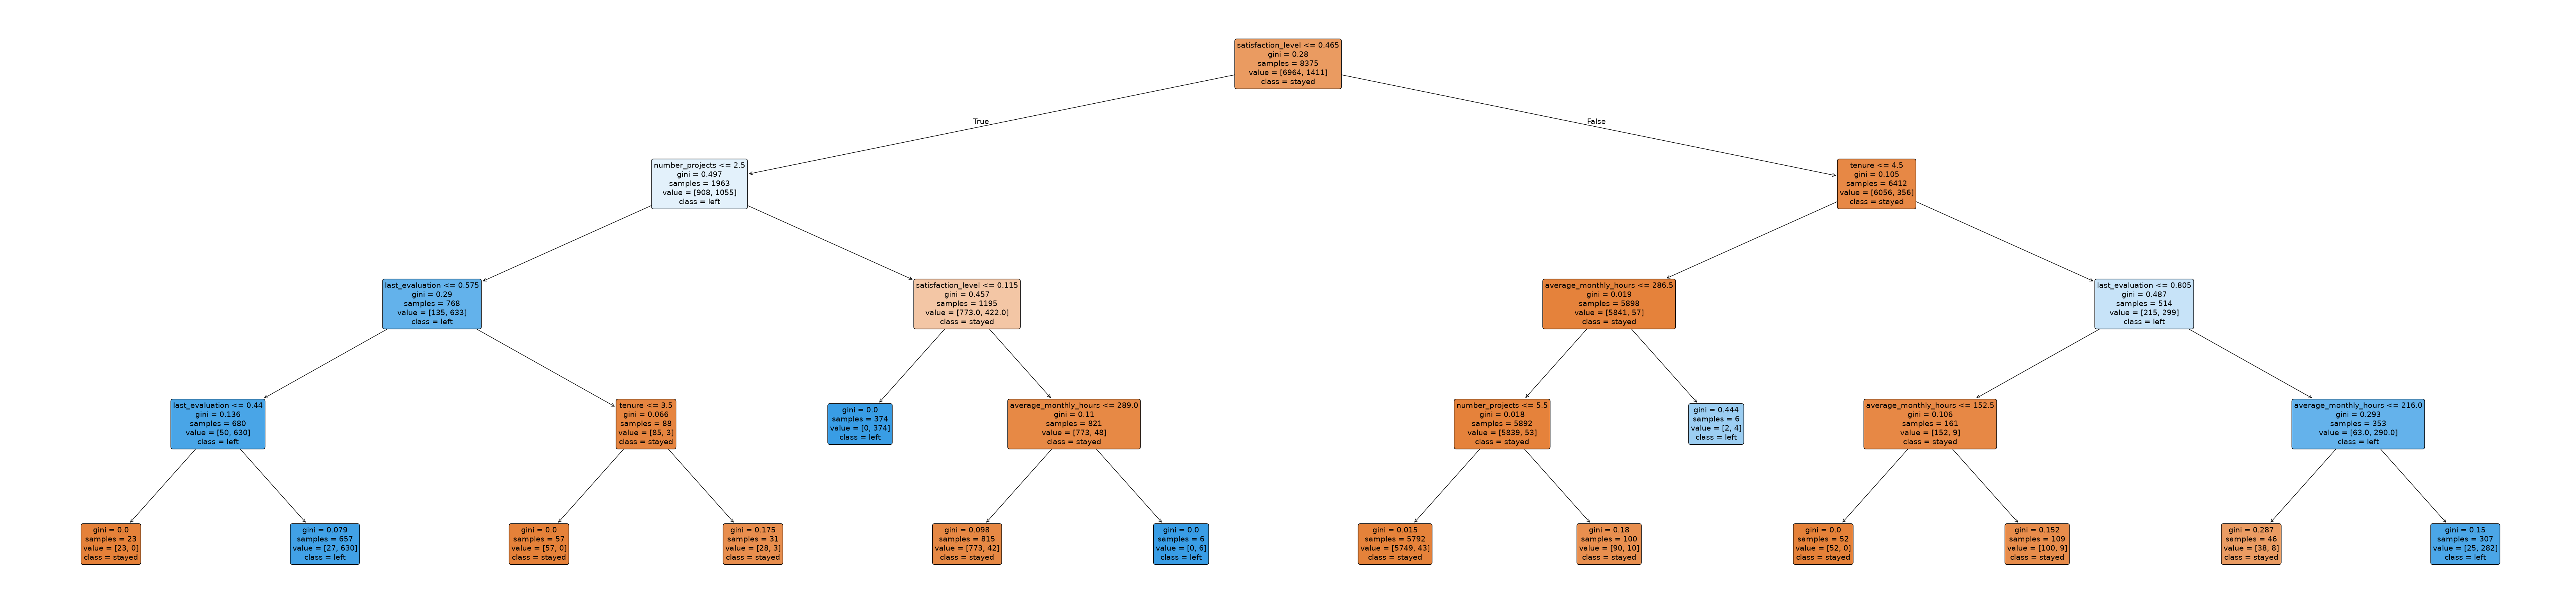

In [53]:
plt.figure(figsize=(85, 20))
plot_tree(
    tree_cv.best_estimator_,
    max_depth=6,
    fontsize=14,
    feature_names=list(X.columns),
    class_names=['stayed', 'left'],
    filled=True,
    rounded=True
)
plt.show()

In [54]:
importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': tree_cv.best_estimator_.feature_importances_
})

importance_df.sort_values(
    by='Importance',
    ascending=False
)

,Feature,Importance
0,satisfaction_level,0.568864
4,tenure,0.152767
1,last_evaluation,0.145263
2,number_projects,0.103151
3,average_monthly_hours,0.029955
5,work_accident,0.000000
6,promotion_last_5_years,0.000000
7,salary,0.000000
8,department_RandD,0.000000
9,department_accounting,0.000000


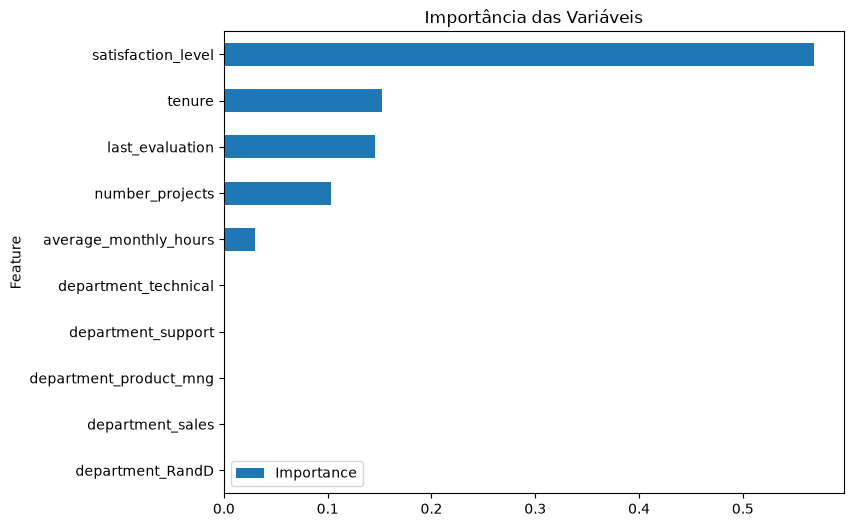

In [55]:
importance_df.sort_values(
    by='Importance'
).tail(10).plot(
    x='Feature',
    y='Importance',
    kind='barh',
    figsize=(8,6)
)

plt.title('Importância das Variáveis')
plt.show()

Na Árvore de Decisão, `satisfaction_level` tem importância de 0,57, mais de três vezes a da segunda variável, `tenure` (0,15). Na Random Forest, a diferença é menor: 0,36 contra 0,20 de `number_projects`, cerca de 1,8 vez. Isso indica que a satisfação é o fator mais relevante, mas o tamanho da vantagem depende do algoritmo. Iniciativas voltadas à satisfação podem ter impacto importante na retenção, sem que isso prove causalidade.


### Random forest

In [56]:
# Criar modelo Random Forest

rf = RandomForestClassifier(random_state=42)

In [57]:
cv_params = {
    'max_depth': [3, 5, None],
    'min_samples_leaf': [1, 2, 3],
    'min_samples_split': [2, 3, 4],
    'n_estimators': [100, 300]
}

scoring = [
    'accuracy',
    'precision',
    'recall',
    'f1',
    'roc_auc'
]

rf_cv = GridSearchCV(
    rf,
    cv_params,
    scoring=scoring,
    cv=5,
    refit='roc_auc',
    n_jobs=4
)

In [58]:
rf_cv.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [3, 5, ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 3, ...], 'n_estimators': [100, 300]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","['accuracy', 'precision', ...]"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",4
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'roc_auc'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from

In [59]:
rf_cv.best_params_

{'max_depth': None,
 'min_samples_leaf': 3,
 'min_samples_split': 2,
 'n_estimators': 300}

In [60]:
rf_cv.best_score_

np.float64(0.9815924618837559)

In [61]:
rf_pred = rf_cv.best_estimator_.predict(X_test)

In [62]:
print(classification_report(y_test, rf_pred))

              precision    recall  f1-score   support

           0       0.98      1.00      0.99      2321
           1       0.99      0.92      0.95       471

    accuracy                           0.98      2792
   macro avg       0.99      0.96      0.97      2792
weighted avg       0.98      0.98      0.98      2792



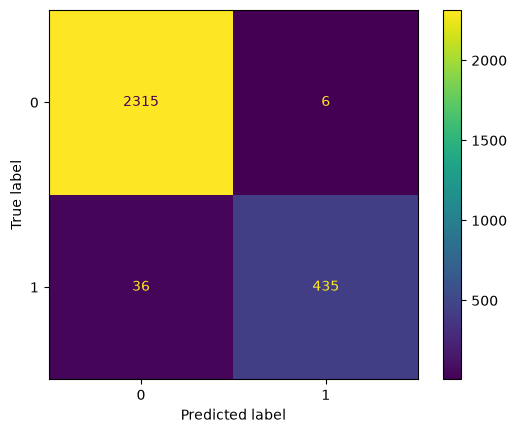

In [63]:
rf_cm = confusion_matrix(y_test, rf_pred)

rf_disp = ConfusionMatrixDisplay(
    confusion_matrix=rf_cm, display_labels=rf_cv.classes_
)

rf_disp.plot(values_format='')

plt.show()

In [64]:
# Avaliar importância das variáveis

rf_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_cv.best_estimator_.feature_importances_
})

rf_importance.sort_values(
    by='Importance',
    ascending=False
)

,Feature,Importance
0,satisfaction_level,0.360705
2,number_projects,0.204356
4,tenure,0.164086
3,average_monthly_hours,0.137880
1,last_evaluation,0.112522
5,work_accident,0.006863
7,salary,0.005719
14,department_sales,0.001754
16,department_technical,0.001329
15,department_support,0.001166


### XGBoost

Ajustamos agora um modelo de *Gradient Boosting* (**XGBoost**) no conjunto completo de preditores (Modelo A), utilizando `GridSearchCV` com validação cruzada de 5 *folds* otimizada por `ROC-AUC`.

In [65]:
# Criar e otimizar modelo XGBoost — Modelo A
xgb = XGBClassifier(
    objective='binary:logistic',
    eval_metric='logloss',
    n_jobs=1,
    random_state=42
)

xgb_cv_params = {
    'max_depth': [4, 6, 8],
    'min_child_weight': [1, 3, 5],
    'learning_rate': [0.1, 0.2],
    'n_estimators': [100, 200]
}

xgb_cv = GridSearchCV(
    xgb,
    xgb_cv_params,
    scoring=scoring,
    cv=5,
    refit='roc_auc',
    n_jobs=4
)

xgb_cv.fit(X_train, y_train)
print('Melhores parâmetros — XGBoost A:', xgb_cv.best_params_)
print('Melhor ROC-AUC (CV treino):', round(xgb_cv.best_score_, 4))


Melhores parâmetros — XGBoost A: {'learning_rate': 0.1, 'max_depth': 4, 'min_child_weight': 1, 'n_estimators': 100}
Melhor ROC-AUC (CV treino): 0.987


              precision    recall  f1-score   support

           0       0.99      0.99      0.99      2321
           1       0.97      0.94      0.95       471

    accuracy                           0.98      2792
   macro avg       0.98      0.97      0.97      2792
weighted avg       0.98      0.98      0.98      2792

ROC-AUC (teste): 0.9895


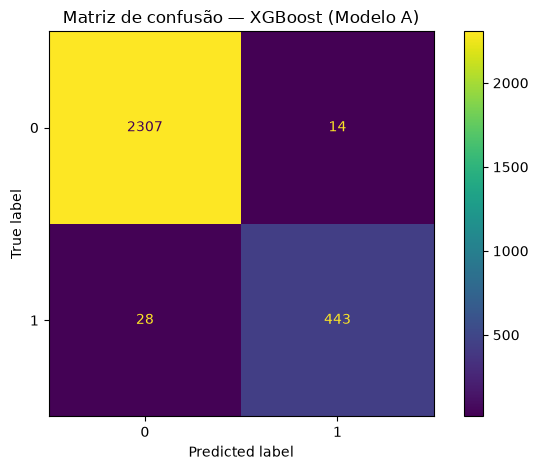

In [66]:
# Avaliar XGBoost A no conjunto de teste
xgb_pred = xgb_cv.best_estimator_.predict(X_test)
xgb_prob = xgb_cv.best_estimator_.predict_proba(X_test)[:, 1]

print(classification_report(y_test, xgb_pred, zero_division=0))
print('ROC-AUC (teste):', round(roc_auc_score(y_test, xgb_prob), 4))

xgb_cm = confusion_matrix(y_test, xgb_pred, labels=xgb_cv.best_estimator_.classes_)
xgb_disp = ConfusionMatrixDisplay(
    confusion_matrix=xgb_cm,
    display_labels=xgb_cv.best_estimator_.classes_
)
xgb_disp.plot(values_format='d')
plt.title('Matriz de confusão — XGBoost (Modelo A)')
plt.tight_layout()
plt.show()


,Feature,Importance
0,tenure,0.410491
1,satisfaction_level,0.317295
2,number_projects,0.103662
3,last_evaluation,0.078666
4,average_monthly_hours,0.033009
5,work_accident,0.019111
6,salary,0.016347
7,department_accounting,0.007238
8,department_product_mng,0.005832
9,department_sales,0.005357


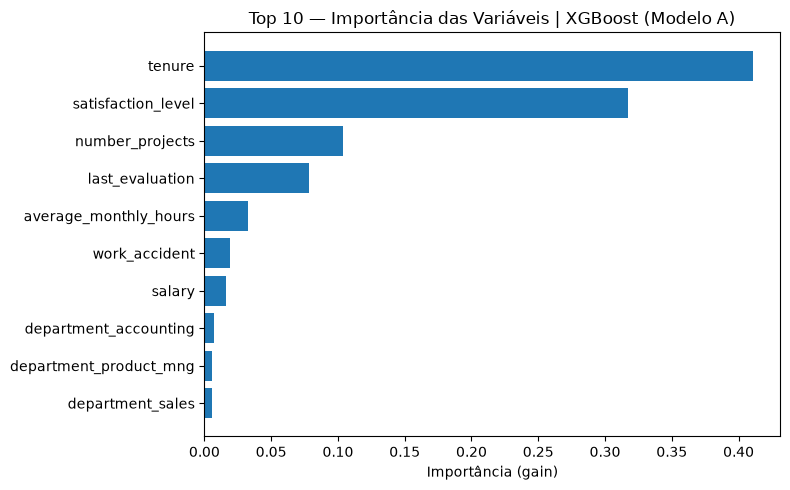

In [67]:
# Importância das variáveis no XGBoost (ganho médio por divisão)
xgb_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': xgb_cv.best_estimator_.feature_importances_
}).sort_values(by='Importance', ascending=False).reset_index(drop=True)

display(xgb_importance.head(10))

xgb_top10 = xgb_importance.head(10).sort_values('Importance', ascending=True)
plt.figure(figsize=(8, 5))
plt.barh(xgb_top10['Feature'], xgb_top10['Importance'])
plt.title('Top 10 — Importância das Variáveis | XGBoost (Modelo A)')
plt.xlabel('Importância (gain)')
plt.tight_layout()
plt.show()


**Observação — XGBoost (Modelo A):**

- O **XGBoost** obteve o maior **ROC-AUC (98,95%)**, **Recall (94,06%)** e **F1-score (95,47%)** da primeira rodada, empatando em **acurácia (98,50%)** com a Random Forest (que teve precision ligeiramente superior: 98,64% vs. 96,94%).
- Na importância por ganho médio (*gain*), `tenure` (0,41) e `satisfaction_level` (0,32) concentram o maior ganho informativo nas divisões sequenciais das árvores, seguidas por `number_projects` (0,10) e `last_evaluation` (0,08). Diferentemente da impureza de Gini na Árvore/Random Forest — que tende a dar maior peso acumulado a variáveis contínuas com muitos pontos de corte como `satisfaction_level` — o critério de *gain* destaca o forte poder discriminativo dos cortes em `tenure` combinados à satisfação.


In [68]:
log_results = pd.DataFrame({
    'Model': ['Logistic Regression'],
    'Accuracy': [accuracy_score(y_test, y_pred)],
    'Precision': [precision_score(y_test, y_pred, zero_division=0)],
    'Recall': [recall_score(y_test, y_pred, zero_division=0)],
    'F1': [f1_score(y_test, y_pred, zero_division=0)],
    'ROC-AUC': [roc_auc_score(y_test, log_clf.predict_proba(X_test)[:, 1])]
})
tree_results = pd.DataFrame({
    'Model': ['Decision Tree'],
    'Accuracy': [accuracy_score(y_test, tree_pred)],
    'Precision': [precision_score(y_test, tree_pred, zero_division=0)],
    'Recall': [recall_score(y_test, tree_pred, zero_division=0)],
    'F1': [f1_score(y_test, tree_pred, zero_division=0)],
    'ROC-AUC': [roc_auc_score(y_test, tree_cv.best_estimator_.predict_proba(X_test)[:, 1])]
})
rf_results = pd.DataFrame({
    'Model': ['Random Forest'],
    'Accuracy': [accuracy_score(y_test, rf_pred)],
    'Precision': [precision_score(y_test, rf_pred, zero_division=0)],
    'Recall': [recall_score(y_test, rf_pred, zero_division=0)],
    'F1': [f1_score(y_test, rf_pred, zero_division=0)],
    'ROC-AUC': [roc_auc_score(y_test, rf_cv.best_estimator_.predict_proba(X_test)[:, 1])]
})
xgb_results = pd.DataFrame({
    'Model': ['XGBoost'],
    'Accuracy': [accuracy_score(y_test, xgb_pred)],
    'Precision': [precision_score(y_test, xgb_pred, zero_division=0)],
    'Recall': [recall_score(y_test, xgb_pred, zero_division=0)],
    'F1': [f1_score(y_test, xgb_pred, zero_division=0)],
    'ROC-AUC': [roc_auc_score(y_test, xgb_prob)]
})
model_comparison = pd.concat([log_results, tree_results, rf_results, xgb_results], ignore_index=True)
model_comparison.sort_values('ROC-AUC', ascending=False).reset_index(drop=True).round(4)


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,XGBoost,0.9850,0.9694,0.9406,0.9547,0.9895
1,Random Forest,0.9850,0.9864,0.9236,0.9539,0.9847
2,Decision Tree,0.9814,0.9584,0.9299,0.9440,0.9779
3,Logistic Regression,0.8256,0.4667,0.2378,0.3150,0.8923


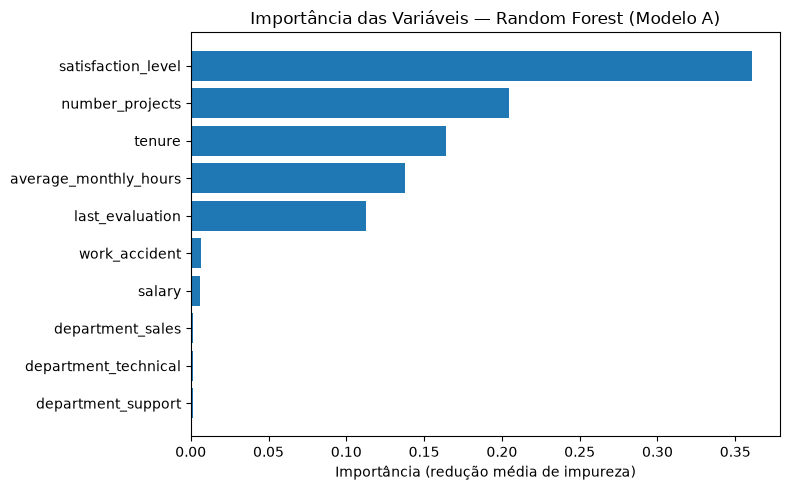

In [69]:
# Visualizar Top 10 variáveis mais importantes na Random Forest (Modelo A)
rf_top10 = rf_importance.sort_values('Importance', ascending=True).tail(10)
plt.figure(figsize=(8, 5))
plt.barh(rf_top10['Feature'], rf_top10['Importance'])
plt.title('Importância das Variáveis — Random Forest (Modelo A)')
plt.xlabel('Importância (redução média de impureza)')
plt.tight_layout()
plt.show()


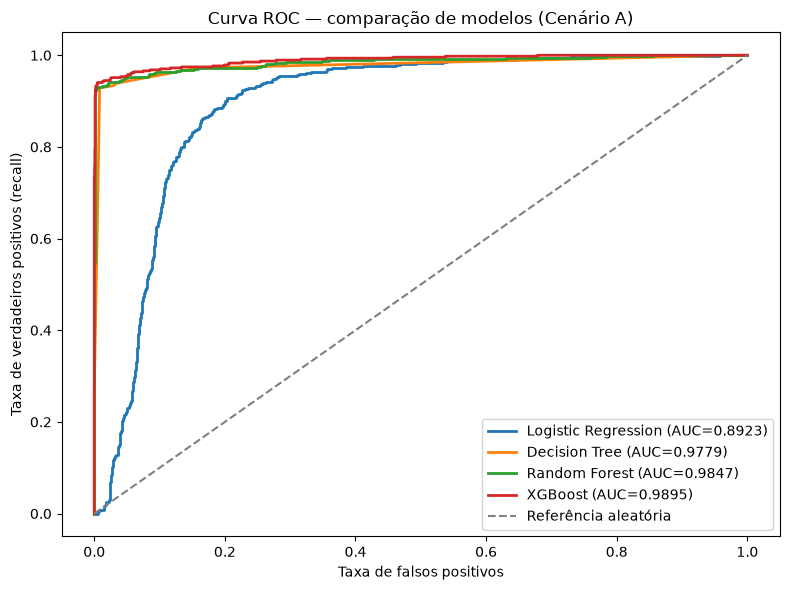

In [70]:
# Curva ROC — comparação dos quatro modelos do Cenário A
plt.figure(figsize=(8, 6))
for nome, modelo in [
    ('Logistic Regression', log_clf),
    ('Decision Tree', tree_cv.best_estimator_),
    ('Random Forest', rf_cv.best_estimator_),
    ('XGBoost', xgb_cv.best_estimator_)
]:
    prob = modelo.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc = roc_auc_score(y_test, prob)
    plt.plot(fpr, tpr, linewidth=2, label=f'{nome} (AUC={auc:.4f})')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Referência aleatória')
plt.xlabel('Taxa de falsos positivos')
plt.ylabel('Taxa de verdadeiros positivos (recall)')
plt.title('Curva ROC — comparação de modelos (Cenário A)')
plt.legend()
plt.tight_layout()
plt.show()


### Feature Engineering

In [71]:
# Drop satisfaction_level
df2 = df_clean.drop('satisfaction_level', axis=1).copy()

# Display data
display(df2.head())

,last_evaluation,number_projects,average_monthly_hours,tenure,work_accident,left,promotion_last_5_years,department,salary
0,0.53,2,157,3,0,1,0,sales,low
1,0.86,5,262,6,0,1,0,sales,medium
2,0.88,7,272,4,0,1,0,sales,medium
3,0.87,5,223,5,0,1,0,sales,low
4,0.52,2,159,3,0,1,0,sales,low


#### Model B & C

A primeira rodada de modelagem funciona como Modelo A (baseline). Nesta etapa, vamos testar duas alternativas para investigar a dependência de variáveis que podem não estar disponíveis ou ser adequadas no momento da previsão:
- Modelo B: remove satisfaction_level, mantendo average_monthly_hours.
- Modelo C: remove satisfaction_level e substitui average_monthly_hours por overworked, que vale 1 quando a média mensal é superior a 175 horas e 0 caso contrário.
Essa comparação é um experimento, não uma suposição de que essas variáveis necessariamente causam vazamento de dados. O ideal é que todas as variáveis usadas estejam disponíveis no momento em que a previsão será feita.

Para manter a comparação justa, os modelos B e C usam os mesmos registros de df_model e a mesma estratégia de divisão treino/teste do Modelo A.

#### Model B

In [72]:
# Drop satisfaction_level
df_model_b = df_model.drop(columns=['satisfaction_level']).copy()

y_b = df_model_b['left']
X_b = df_model_b.drop(columns=['left'])

X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(
    X_b, y_b,
    test_size=0.25,
    random_state=0,
    stratify=y_b
)

print("Modelo B — treino:", X_train_b.shape)
print("Modelo B — teste:", X_test_b.shape)
display(df_model_b.head())

Modelo B — treino: (8375, 16)
Modelo B — teste: (2792, 16)


,last_evaluation,number_projects,average_monthly_hours,tenure,work_accident,left,promotion_last_5_years,salary,department_RandD,department_accounting,department_hr,department_management,department_marketing,department_product_mng,department_sales,department_support,department_technical
0,0.53,2,157,3,0,1,0,0,False,False,False,False,False,False,True,False,False
2,0.88,7,272,4,0,1,0,1,False,False,False,False,False,False,True,False,False
3,0.87,5,223,5,0,1,0,0,False,False,False,False,False,False,True,False,False
4,0.52,2,159,3,0,1,0,0,False,False,False,False,False,False,True,False,False
5,0.50,2,153,3,0,1,0,0,False,False,False,False,False,False,True,False,False


##### Decision Tree

In [73]:
# Decision Tree - Model B
tree_b = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    {
        'max_depth': [4, 6, 8, None],
        'min_samples_leaf': [1, 2, 5],
        'min_samples_split': [2, 4, 6]
    },
    scoring='roc_auc',
    cv=5,
    refit=True,
    n_jobs=4
)
tree_b.fit(X_train_b, y_train_b)

tree_b_pred = tree_b.best_estimator_.predict(X_test_b)
tree_b_prob = tree_b.best_estimator_.predict_proba(X_test_b)[:, 1]


In [74]:
# Check best params
tree_b.best_score_

np.float64(0.9650655160370393)

In [75]:
print("Melhores parâmetros — Árvore B:", tree_b.best_params_)
print(classification_report(y_test_b, tree_b_pred, zero_division=0))

Melhores parâmetros — Árvore B: {'max_depth': 6, 'min_samples_leaf': 1, 'min_samples_split': 4}
              precision    recall  f1-score   support

           0       0.98      0.99      0.99      2321
           1       0.95      0.93      0.94       471

    accuracy                           0.98      2792
   macro avg       0.97      0.96      0.96      2792
weighted avg       0.98      0.98      0.98      2792



In [76]:
print("ROC-AUC:", round(roc_auc_score(y_test_b, tree_b_prob), 4))

ROC-AUC: 0.9766


#### Random Forest

In [77]:
# Random Forest — Model B
rf_b = GridSearchCV(
    RandomForestClassifier(random_state=42),
    {
        'max_depth': [3, 5, None],
        'min_samples_leaf': [1, 2, 3],
        'min_samples_split': [2, 3, 4],
        'n_estimators': [100, 300]
    },
    scoring='roc_auc',
    cv=5,
    refit=True,
    n_jobs=4
)
rf_b.fit(X_train_b, y_train_b)

rf_b_pred = rf_b.best_estimator_.predict(X_test_b)
rf_b_prob = rf_b.best_estimator_.predict_proba(X_test_b)[:, 1]


In [78]:
rf_b.best_score_

np.float64(0.9745059813668341)

In [79]:

print("Melhores parâmetros — Random Forest B:", rf_b.best_params_)
print(classification_report(y_test_b, rf_b_pred, zero_division=0))

Melhores parâmetros — Random Forest B: {'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 300}
              precision    recall  f1-score   support

           0       0.94      0.99      0.96      2321
           1       0.94      0.69      0.80       471

    accuracy                           0.94      2792
   macro avg       0.94      0.84      0.88      2792
weighted avg       0.94      0.94      0.94      2792



In [80]:

print("ROC-AUC:", round(roc_auc_score(y_test_b, rf_b_prob), 4))

ROC-AUC: 0.9765


#### XGBoost

In [81]:
# XGBoost — Model B (sem satisfaction_level)
xgb_b = GridSearchCV(
    XGBClassifier(
        objective='binary:logistic',
        eval_metric='logloss',
        n_jobs=1,
        random_state=42
    ),
    xgb_cv_params,
    scoring='roc_auc',
    cv=5,
    refit=True,
    n_jobs=4
)
xgb_b.fit(X_train_b, y_train_b)

xgb_b_pred = xgb_b.best_estimator_.predict(X_test_b)
xgb_b_prob = xgb_b.best_estimator_.predict_proba(X_test_b)[:, 1]

print('Melhores parâmetros — XGBoost B:', xgb_b.best_params_)
print('Melhor ROC-AUC (CV treino):', round(xgb_b.best_score_, 4))
print(classification_report(y_test_b, xgb_b_pred, zero_division=0))
print('ROC-AUC (teste):', round(roc_auc_score(y_test_b, xgb_b_prob), 4))


Melhores parâmetros — XGBoost B: {'learning_rate': 0.1, 'max_depth': 4, 'min_child_weight': 1, 'n_estimators': 100}
Melhor ROC-AUC (CV treino): 0.9778
              precision    recall  f1-score   support

           0       0.98      0.99      0.99      2321
           1       0.94      0.93      0.93       471

    accuracy                           0.98      2792
   macro avg       0.96      0.96      0.96      2792
weighted avg       0.98      0.98      0.98      2792

ROC-AUC (teste): 0.9835


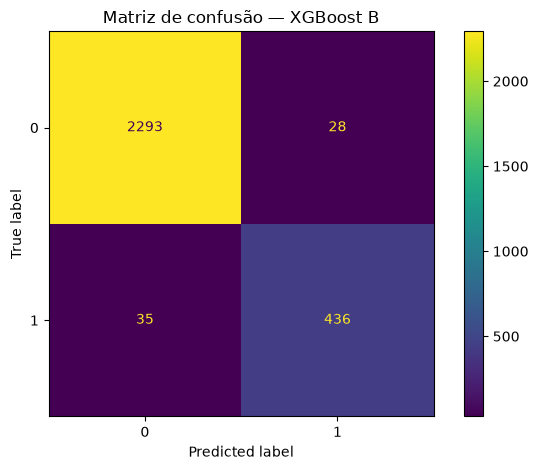

In [82]:
# Matriz de confusão para o Modelo B — XGBoost
xgb_b_cm = confusion_matrix(y_test_b, xgb_b_pred, labels=xgb_b.best_estimator_.classes_)
xgb_b_disp = ConfusionMatrixDisplay(
    confusion_matrix=xgb_b_cm,
    display_labels=xgb_b.best_estimator_.classes_
)
xgb_b_disp.plot(values_format='d')
plt.title('Matriz de confusão — XGBoost B')
plt.tight_layout()
plt.show()


In [83]:
tree_b_results = pd.DataFrame({
    'Model': ['Decision Tree'],
    'Accuracy': [accuracy_score(y_test_b, tree_b_pred)],
    'Precision': [precision_score(y_test_b, tree_b_pred, zero_division=0)],
    'Recall': [recall_score(y_test_b, tree_b_pred, zero_division=0)],
    'F1': [f1_score(y_test_b, tree_b_pred, zero_division=0)],
    'ROC-AUC': [roc_auc_score(y_test_b, tree_b_prob)]
})
rf_b_results = pd.DataFrame({
    'Model': ['Random Forest'],
    'Accuracy': [accuracy_score(y_test_b, rf_b_pred)],
    'Precision': [precision_score(y_test_b, rf_b_pred, zero_division=0)],
    'Recall': [recall_score(y_test_b, rf_b_pred, zero_division=0)],
    'F1': [f1_score(y_test_b, rf_b_pred, zero_division=0)],
    'ROC-AUC': [roc_auc_score(y_test_b, rf_b_prob)]
})
xgb_b_results = pd.DataFrame({
    'Model': ['XGBoost'],
    'Accuracy': [accuracy_score(y_test_b, xgb_b_pred)],
    'Precision': [precision_score(y_test_b, xgb_b_pred, zero_division=0)],
    'Recall': [recall_score(y_test_b, xgb_b_pred, zero_division=0)],
    'F1': [f1_score(y_test_b, xgb_b_pred, zero_division=0)],
    'ROC-AUC': [roc_auc_score(y_test_b, xgb_b_prob)]
})
model_comparison_b = pd.concat([tree_b_results, rf_b_results, xgb_b_results], ignore_index=True)
model_comparison_b.sort_values('ROC-AUC', ascending=False).reset_index(drop=True).round(4)


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,XGBoost,0.9774,0.9397,0.9257,0.9326,0.9835
1,Decision Tree,0.9792,0.9499,0.9257,0.9376,0.9766
2,Random Forest,0.9402,0.9393,0.6900,0.7956,0.9765


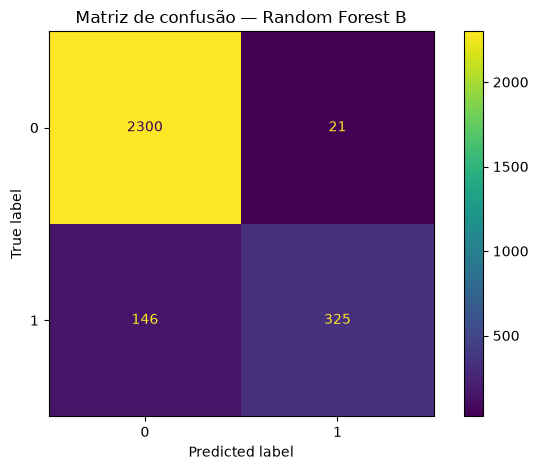

In [84]:
# Matriz de confusão correta para o Modelo B — Random Forest
rf_b_cm = confusion_matrix(y_test_b, rf_b_pred, labels=rf_b.best_estimator_.classes_)
rf_b_disp = ConfusionMatrixDisplay(
    confusion_matrix=rf_b_cm,
    display_labels=rf_b.best_estimator_.classes_
)
rf_b_disp.plot(values_format='d')
plt.title('Matriz de confusão — Random Forest B')
plt.tight_layout()
plt.show()

#### Model C

criar a variável overworked
Neste cenário, além de remover satisfaction_level, transformamos as horas mensais em uma variável binária. O limite de 175 horas é uma regra operacional usada neste experimento; vale documentar que esse limite é uma simplificação e pode perder diferenças entre jornadas.

In [85]:
# Drop satisfaction_level
df_model_c = df_model.drop(columns=['satisfaction_level']).copy()

# Create column overworked
df_model_c['overworked'] = (
    df_model_c['average_monthly_hours'] > 175
).astype(int)

# Drop variable average_monthly_hours
df_model_c = df_model_c.drop(columns=['average_monthly_hours'])

y_c = df_model_c['left']
X_c = df_model_c.drop(columns=['left'])

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_c, y_c,
    test_size=0.25,
    random_state=0,
    stratify=y_c
)

print("Distribuição de overworked:")
display(df_model_c['overworked'].value_counts().rename_axis('overworked').to_frame('quantidade'))
print("Modelo C — treino:", X_train_c.shape)
print("Modelo C — teste:", X_test_c.shape)
display(df_model_c.head())

Distribuição de overworked:


,quantidade
overworked,
1,7062
0,4105


Modelo C — treino: (8375, 16)
Modelo C — teste: (2792, 16)


,last_evaluation,number_projects,tenure,work_accident,left,promotion_last_5_years,salary,department_RandD,department_accounting,department_hr,department_management,department_marketing,department_product_mng,department_sales,department_support,department_technical,overworked
0,0.53,2,3,0,1,0,0,False,False,False,False,False,False,True,False,False,0
2,0.88,7,4,0,1,0,1,False,False,False,False,False,False,True,False,False,1
3,0.87,5,5,0,1,0,0,False,False,False,False,False,False,True,False,False,1
4,0.52,2,3,0,1,0,0,False,False,False,False,False,False,True,False,False,0
5,0.50,2,3,0,1,0,0,False,False,False,False,False,False,True,False,False,0


#### Decision Tree

In [86]:
# Decision tree
tree_c = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    {
        'max_depth': [4, 6, 8, None],
        'min_samples_leaf': [1, 2, 5],
        'min_samples_split': [2, 4, 6]
    },
    scoring='roc_auc',
    cv=5,
    refit=True,
    n_jobs=4
)
tree_c.fit(X_train_c, y_train_c)

tree_c_pred = tree_c.best_estimator_.predict(X_test_c)
tree_c_prob = tree_c.best_estimator_.predict_proba(X_test_c)[:, 1]

print("Melhores parâmetros — Árvore C:", tree_c.best_params_)
print(classification_report(y_test_c, tree_c_pred, zero_division=0))
print("ROC-AUC:", round(roc_auc_score(y_test_c, tree_c_prob), 4))

Melhores parâmetros — Árvore C: {'max_depth': 4, 'min_samples_leaf': 1, 'min_samples_split': 2}
              precision    recall  f1-score   support

           0       0.98      0.97      0.98      2321
           1       0.85      0.92      0.88       471

    accuracy                           0.96      2792
   macro avg       0.92      0.94      0.93      2792
weighted avg       0.96      0.96      0.96      2792

ROC-AUC: 0.9644


#### Random Forest

In [87]:
# Random Forest
rf_c = GridSearchCV(
    RandomForestClassifier(random_state=42),
    {
        'max_depth': [3, 5, None],
        'min_samples_leaf': [1, 2, 3],
        'min_samples_split': [2, 3, 4],
        'n_estimators': [100, 300]
    },
    scoring='roc_auc',
    cv=5,
    refit=True,
    n_jobs=4
)
rf_c.fit(X_train_c, y_train_c)

rf_c_pred = rf_c.best_estimator_.predict(X_test_c)
rf_c_prob = rf_c.best_estimator_.predict_proba(X_test_c)[:, 1]

print("Melhores parâmetros — Random Forest C:", rf_c.best_params_)
print(classification_report(y_test_c, rf_c_pred, zero_division=0))
print("ROC-AUC:", round(roc_auc_score(y_test_c, rf_c_prob), 4))

Melhores parâmetros — Random Forest C: {'max_depth': 5, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 100}
              precision    recall  f1-score   support

           0       0.94      0.99      0.96      2321
           1       0.91      0.67      0.77       471

    accuracy                           0.93      2792
   macro avg       0.92      0.83      0.87      2792
weighted avg       0.93      0.93      0.93      2792

ROC-AUC: 0.9711


#### XGBoost

In [88]:
# XGBoost — Model C (sem satisfaction_level + variável overworked)
xgb_c = GridSearchCV(
    XGBClassifier(
        objective='binary:logistic',
        eval_metric='logloss',
        n_jobs=1,
        random_state=42
    ),
    xgb_cv_params,
    scoring='roc_auc',
    cv=5,
    refit=True,
    n_jobs=4
)
xgb_c.fit(X_train_c, y_train_c)

xgb_c_pred = xgb_c.best_estimator_.predict(X_test_c)
xgb_c_prob = xgb_c.best_estimator_.predict_proba(X_test_c)[:, 1]

print("Melhores parâmetros — XGBoost C:", xgb_c.best_params_)
print(classification_report(y_test_c, xgb_c_pred, zero_division=0))
print("ROC-AUC:", round(roc_auc_score(y_test_c, xgb_c_prob), 4))


Melhores parâmetros — XGBoost C: {'learning_rate': 0.1, 'max_depth': 4, 'min_child_weight': 1, 'n_estimators': 100}
              precision    recall  f1-score   support

           0       0.98      0.98      0.98      2321
           1       0.91      0.91      0.91       471

    accuracy                           0.97      2792
   macro avg       0.95      0.95      0.95      2792
weighted avg       0.97      0.97      0.97      2792

ROC-AUC: 0.9767


### ✍️ Registro do Modelo C — engenharia de atributos

- `average_monthly_hours` foi substituída por `overworked`, que vale 1 quando as horas mensais são superiores a 175 e 0 caso contrário. A simplificação foi testada para verificar se um indicador binário de sobrecarga basta.
- O que se perde: as diferenças de intensidade da jornada. Por exemplo, 180 e 260 horas recebem o mesmo valor, e a subcarga (< 160 horas) fica misturada com a jornada regular (160–175 horas). O limite de 175 horas é uma regra experimental, não um padrão de sobrecarga.
- Resultado: do Modelo B para o Modelo C, houve leve queda em todos os algoritmos — o recall caiu de `0,93` para `0,91` no **XGBoost** (ROC-AUC de `0,9835` para `0,9767`), de `0,69` para `0,67` na **Random Forest**, e de `0,93` para `0,92` na **Árvore de Decisão**, confirmando que a variável contínua `average_monthly_hours` preserva mais informação preditiva.


#### Feature Importance — Modelos B e C

A importância por `feature_importances_` mostra como os modelos baseados em árvores usam as variáveis para reduzir a impureza durante o ajuste. Ela **não demonstra causalidade**, não informa necessariamente a direção da relação e deve ser interpretada com cautela. As importâncias são mais diretamente comparáveis dentro de cada modelo; comparar B e C exige lembrar que os conjuntos de preditores são diferentes.

Observe as variáveis no topo, compare árvore e random forest dentro de cada cenário e verifique se `overworked` resume informação que no Modelo B estava em `average_monthly_hours`. Os resultados abaixo são calculados ao executar a célula.

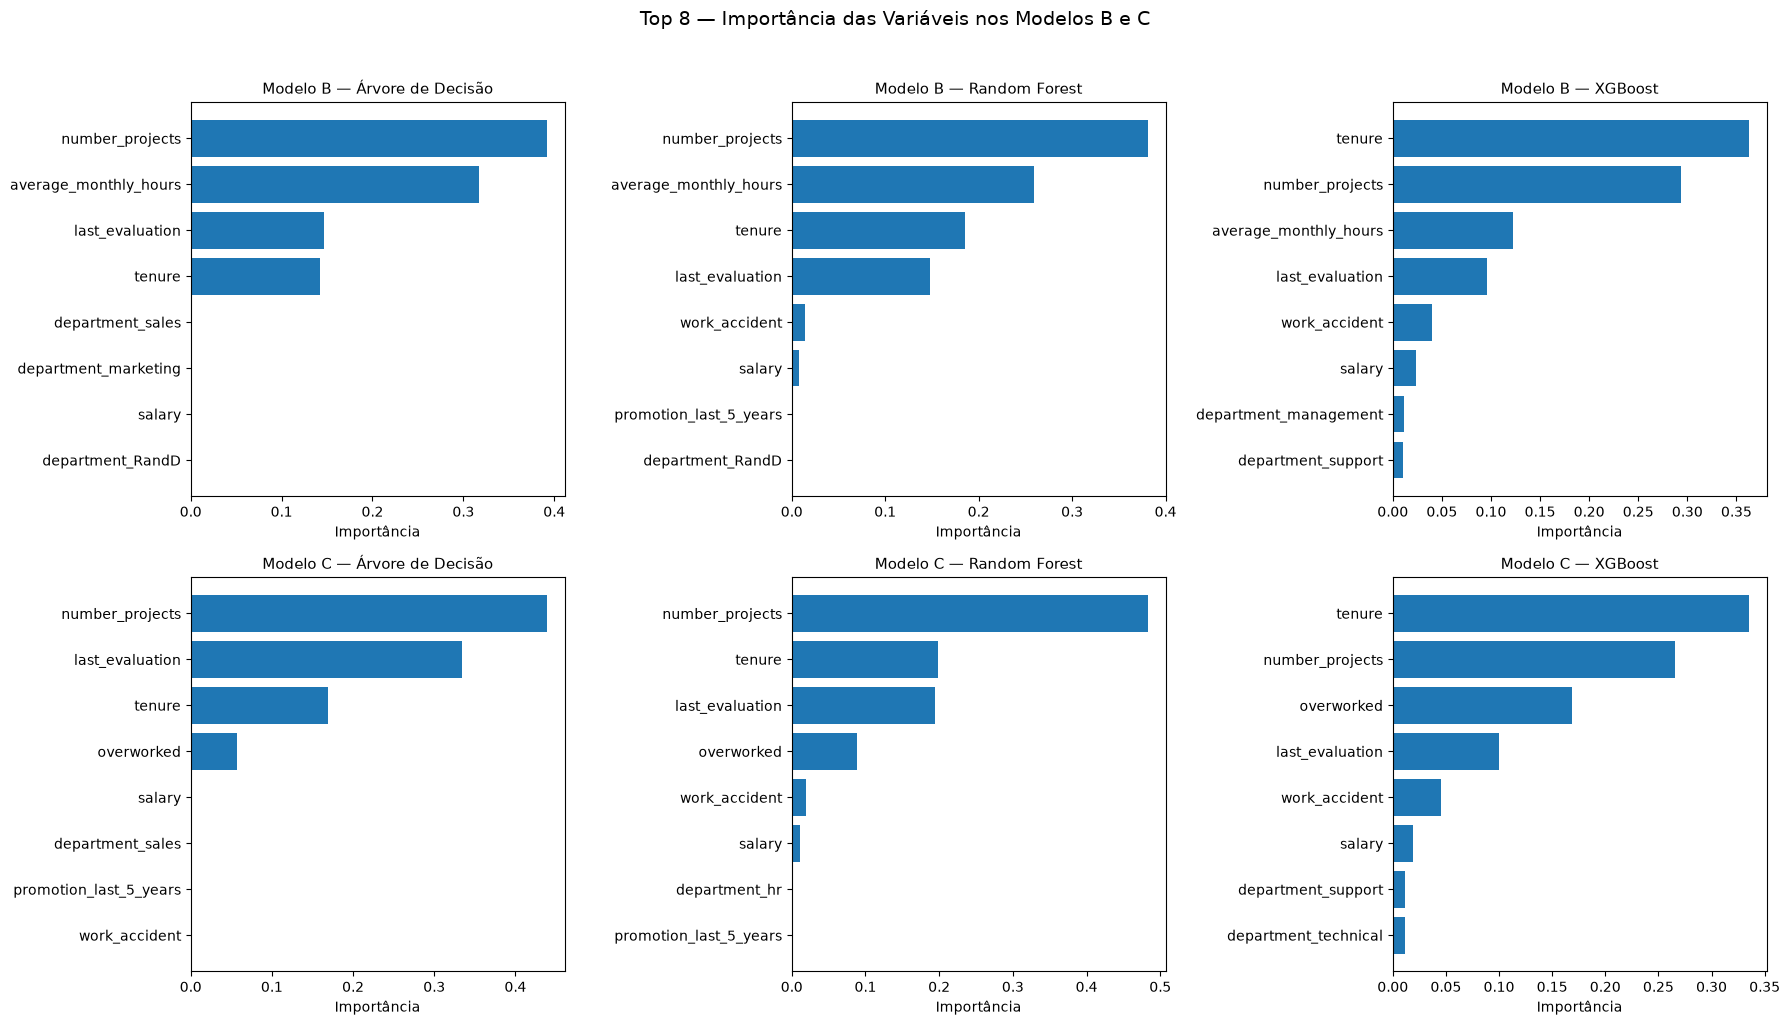


Modelo B — Árvore de Decisão — top 6


,Modelo,Variável,Importância
0,Modelo B — Árvore de Decisão,number_projects,0.3917
1,Modelo B — Árvore de Decisão,average_monthly_hours,0.3173
2,Modelo B — Árvore de Decisão,last_evaluation,0.1466
3,Modelo B — Árvore de Decisão,tenure,0.1418
4,Modelo B — Árvore de Decisão,department_sales,0.0014
5,Modelo B — Árvore de Decisão,department_marketing,0.0006



Modelo B — Random Forest — top 6


,Modelo,Variável,Importância
0,Modelo B — Random Forest,number_projects,0.3810
1,Modelo B — Random Forest,average_monthly_hours,0.2588
2,Modelo B — Random Forest,tenure,0.1854
3,Modelo B — Random Forest,last_evaluation,0.1483
4,Modelo B — Random Forest,work_accident,0.0144
5,Modelo B — Random Forest,salary,0.0080



Modelo B — XGBoost — top 6


,Modelo,Variável,Importância
0,Modelo B — XGBoost,tenure,0.3626
1,Modelo B — XGBoost,number_projects,0.2933
2,Modelo B — XGBoost,average_monthly_hours,0.1226
3,Modelo B — XGBoost,last_evaluation,0.0961
4,Modelo B — XGBoost,work_accident,0.0399
5,Modelo B — XGBoost,salary,0.0233


... (2 outputs left out)


Modelo C — Random Forest — top 6


,Modelo,Variável,Importância
0,Modelo C — Random Forest,number_projects,0.4830
1,Modelo C — Random Forest,tenure,0.1982
2,Modelo C — Random Forest,last_evaluation,0.1937
3,Modelo C — Random Forest,overworked,0.0891
4,Modelo C — Random Forest,work_accident,0.0189
5,Modelo C — Random Forest,salary,0.0118



Modelo C — XGBoost — top 6


,Modelo,Variável,Importância
0,Modelo C — XGBoost,tenure,0.3351
1,Modelo C — XGBoost,number_projects,0.2654
2,Modelo C — XGBoost,overworked,0.1689
3,Modelo C — XGBoost,last_evaluation,0.1002
4,Modelo C — XGBoost,work_accident,0.0449
5,Modelo C — XGBoost,salary,0.0190


In [89]:
# Feature importance dos seis modelos nos cenários B e C
modelos_importancia_bc = [
    ('Modelo B — Árvore de Decisão', tree_b.best_estimator_, X_train_b.columns),
    ('Modelo B — Random Forest', rf_b.best_estimator_, X_train_b.columns),
    ('Modelo B — XGBoost', xgb_b.best_estimator_, X_train_b.columns),
    ('Modelo C — Árvore de Decisão', tree_c.best_estimator_, X_train_c.columns),
    ('Modelo C — Random Forest', rf_c.best_estimator_, X_train_c.columns),
    ('Modelo C — XGBoost', xgb_c.best_estimator_, X_train_c.columns),
]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

lista_importancias_bc = []
for idx, (nome, modelo, colunas) in enumerate(modelos_importancia_bc):
    imp = pd.DataFrame({
        'Modelo': nome,
        'Variável': list(colunas),
        'Importância': modelo.feature_importances_
    }).sort_values('Importância', ascending=False).reset_index(drop=True)
    lista_importancias_bc.append(imp)

    top8 = imp.head(8).sort_values('Importância', ascending=True)
    axes[idx].barh(top8['Variável'], top8['Importância'])
    axes[idx].set_title(nome, fontsize=11)
    axes[idx].set_xlabel('Importância')

plt.suptitle('Top 8 — Importância das Variáveis nos Modelos B e C', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

importancias_bc = pd.concat(lista_importancias_bc, ignore_index=True)
for nome in importancias_bc['Modelo'].drop_duplicates():
    print(f'\n{nome} — top 6')
    display(importancias_bc.loc[importancias_bc['Modelo'] == nome].head(6).reset_index(drop=True).round(4))


### Interpretação da Feature Importance — Modelos B e C

- **Modelo B — Árvore de Decisão:** `number_projects` (0,39), `average_monthly_hours` (0,32) e `last_evaluation` (0,15). Sem a satisfação, a carga de trabalho passa a dominar a árvore.
- **Modelo B — Random Forest:** `number_projects` (0,38), `average_monthly_hours` (0,26) e `tenure` (0,19).
- **Modelo B — XGBoost:** `tenure` (0,36), `number_projects` (0,29), `average_monthly_hours` (0,12) e `last_evaluation` (0,10).
- **Modelo C — Árvore de Decisão:** `number_projects` (0,44), `last_evaluation` (0,33), `tenure` (0,17) e `overworked` (0,06).
- **Modelo C — Random Forest:** `number_projects` (0,48), `tenure` (0,20), `last_evaluation` (0,19) e `overworked` (0,09).
- **Modelo C — XGBoost:** `tenure` (0,34), `number_projects` (0,27), `overworked` (0,17) e `last_evaluation` (0,10).
- **Síntese:** na ausência de `satisfaction_level`, as variáveis ligadas ao volume de trabalho (`number_projects` e `average_monthly_hours`) e ao tempo de empresa (`tenure`) assumem o protagonismo nos três algoritmos. Substituir `average_monthly_hours` pela variável binária `overworked` reduz a capacidade preditiva dos modelos, mostrando que a intensidade contínua da jornada traz informação relevante.

**Cuidados:** importância não significa causa, e diferentes métricas internas (redução de impureza de Gini em Árvore/RF vs. *gain* no XGBoost) ponderam as divisões de maneira distinta. O limite de 175 horas é uma simplificação experimental.


#### Compare the Models (A, B, C)

A tabela abaixo compara os resultados no conjunto de teste. O Modelo A contém os resultados da primeira rodada já calculados anteriormente; B e C são os novos experimentos. A comparação inclui ROC-AUC, precision, recall e F1-score para a classe positiva (left = 1).

Para o problema de rotatividade, o recall da classe 1 é importante porque indica a proporção dos funcionários que saíram e foram identificados corretamente.

In [90]:
def summarize_model(name, y_true, y_pred, y_prob):
    return {
        'Modelo': name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred, zero_division=0),
        'F1-score': f1_score(y_true, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_true, y_prob)
    }

comparison_abc = pd.DataFrame([
    # Modelo A
    summarize_model(
        'A — Regressão Logística',
        y_test, y_pred, log_clf.predict_proba(X_test)[:, 1]
    ),
    summarize_model(
        'A — Árvore de Decisão',
        y_test, tree_pred, tree_cv.best_estimator_.predict_proba(X_test)[:, 1]
    ),
    summarize_model(
        'A — Random Forest',
        y_test, rf_pred, rf_cv.best_estimator_.predict_proba(X_test)[:, 1]
    ),
    summarize_model(
        'A — XGBoost',
        y_test, xgb_pred, xgb_prob
    ),
    # Modelo B
    summarize_model('B — Árvore de Decisão', y_test_b, tree_b_pred, tree_b_prob),
    summarize_model('B — Random Forest', y_test_b, rf_b_pred, rf_b_prob),
    summarize_model('B — XGBoost', y_test_b, xgb_b_pred, xgb_b_prob),
    # Modelo C
    summarize_model('C — Árvore de Decisão', y_test_c, tree_c_pred, tree_c_prob),
    summarize_model('C — Random Forest', y_test_c, rf_c_pred, rf_c_prob),
    summarize_model('C — XGBoost', y_test_c, xgb_c_pred, xgb_c_prob),
])

comparison_abc.sort_values('ROC-AUC', ascending=False).reset_index(drop=True).round(4)


,Modelo,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,A — XGBoost,0.9850,0.9694,0.9406,0.9547,0.9895
1,A — Random Forest,0.9850,0.9864,0.9236,0.9539,0.9847
2,B — XGBoost,0.9774,0.9397,0.9257,0.9326,0.9835
3,A — Árvore de Decisão,0.9814,0.9584,0.9299,0.9440,0.9779
4,C — XGBoost,0.9706,0.9130,0.9130,0.9130,0.9767
5,B — Árvore de Decisão,0.9792,0.9499,0.9257,0.9376,0.9766
6,B — Random Forest,0.9402,0.9393,0.6900,0.7956,0.9765
7,C — Random Forest,0.9330,0.9128,0.6667,0.7706,0.9711
8,C — Árvore de Decisão,0.9588,0.8504,0.9172,0.8825,0.9644
9,A — Regressão Logística,0.8256,0.4667,0.2378,0.3150,0.8923


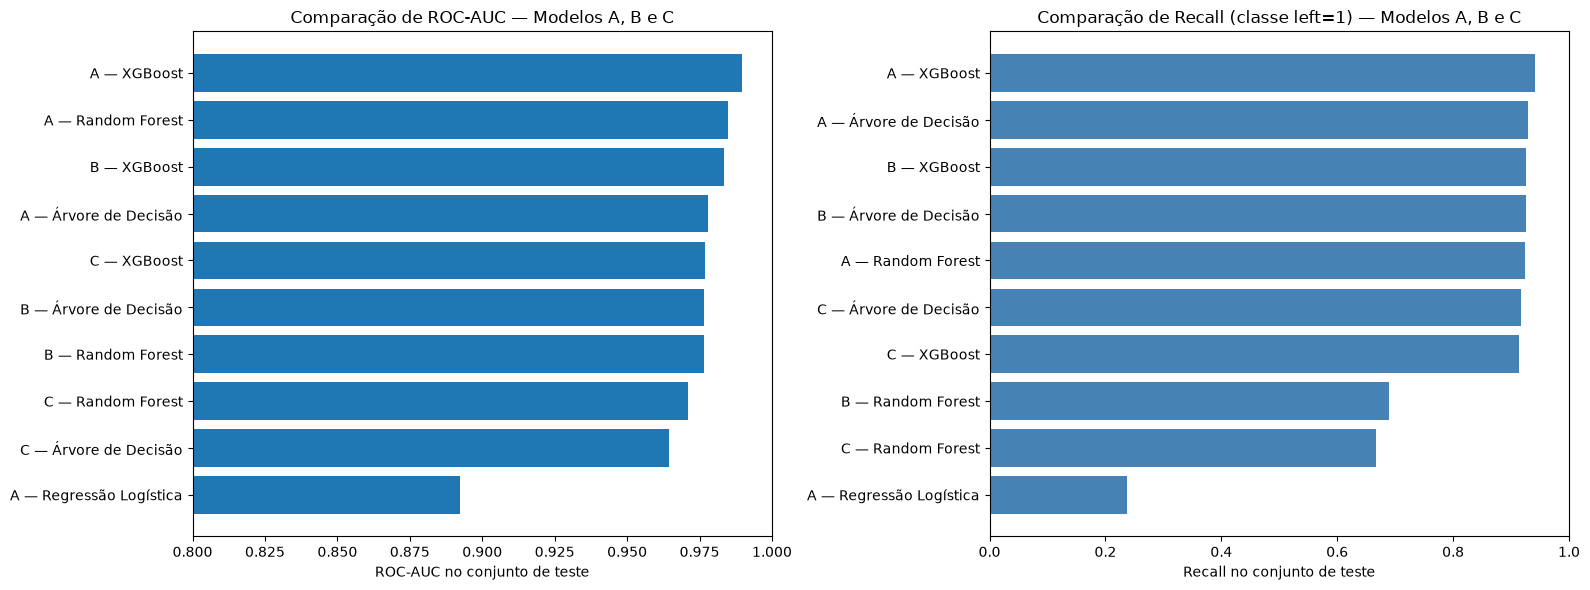

In [91]:
# Visualizar ROC-AUC e F1-score / Recall por Modelo (Cenários A, B e C)
fig, ax = plt.subplots(1, 2, figsize=(16, 6))

plot_auc = comparison_abc.sort_values('ROC-AUC', ascending=True)
ax[0].barh(plot_auc['Modelo'], plot_auc['ROC-AUC'])
ax[0].set_xlim(0.80, 1.0)
ax[0].set_title('Comparação de ROC-AUC — Modelos A, B e C')
ax[0].set_xlabel('ROC-AUC no conjunto de teste')

plot_rec = comparison_abc.sort_values('Recall', ascending=True)
ax[1].barh(plot_rec['Modelo'], plot_rec['Recall'], color='steelblue')
ax[1].set_xlim(0.0, 1.0)
ax[1].set_title('Comparação de Recall (classe left=1) — Modelos A, B e C')
ax[1].set_xlabel('Recall no conjunto de teste')

plt.tight_layout()
plt.show()


#### Ajuste de limiar de decisão (*Threshold*) — Equilíbrio entre Recall e Precision

Por padrão, os classificadores usam o limiar de probabilidade `0,50`. Na prática de People Analytics, caso o RH queira ampliar a cobertura preventiva de equipes sob risco (aumentando o **Recall**) sem comprometer excessivamente a **Precision**, é possível calibrar esse ponto de corte. Avaliamos abaixo esse *trade-off* para o **XGBoost B** (cenário conservador, sem `satisfaction_level`).

,Threshold,Accuracy,Precision,Recall,F1-score
0,0.25,0.9692,0.8889,0.9342,0.9110
1,0.30,0.9717,0.9033,0.9321,0.9175
2,0.35,0.9746,0.9202,0.9299,0.9250
3,0.40,0.9756,0.9260,0.9299,0.9280
4,0.50,0.9774,0.9397,0.9257,0.9326
5,0.60,0.9778,0.9534,0.9130,0.9328


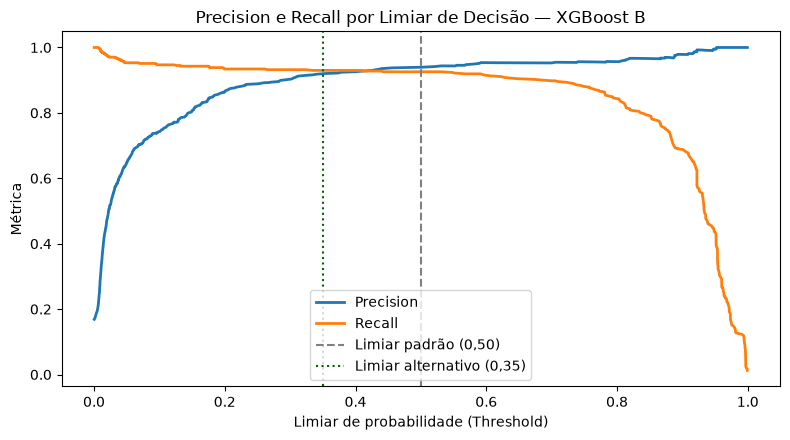

In [92]:
# Avaliar diferentes limiares de decisão no XGBoost B (sem satisfaction_level)
limiares = [0.25, 0.30, 0.35, 0.40, 0.50, 0.60]
linhas_limiar = []
for t in limiares:
    pred_t = (xgb_b_prob >= t).astype(int)
    linhas_limiar.append({
        'Threshold': t,
        'Accuracy': round(accuracy_score(y_test_b, pred_t), 4),
        'Precision': round(precision_score(y_test_b, pred_t, zero_division=0), 4),
        'Recall': round(recall_score(y_test_b, pred_t, zero_division=0), 4),
        'F1-score': round(f1_score(y_test_b, pred_t, zero_division=0), 4),
    })
display(pd.DataFrame(linhas_limiar))

# Curva Precision vs Recall em função do limiar
prec_curve, rec_curve, thr_curve = precision_recall_curve(y_test_b, xgb_b_prob)
plt.figure(figsize=(8, 4.5))
plt.plot(thr_curve, prec_curve[:-1], label='Precision', linewidth=2)
plt.plot(thr_curve, rec_curve[:-1], label='Recall', linewidth=2)
plt.axvline(0.50, linestyle='--', color='gray', label='Limiar padrão (0,50)')
plt.axvline(0.35, linestyle=':', color='darkgreen', label='Limiar alternativo (0,35)')
plt.xlabel('Limiar de probabilidade (Threshold)')
plt.ylabel('Métrica')
plt.title('Precision e Recall por Limiar de Decisão — XGBoost B')
plt.legend()
plt.tight_layout()
plt.show()


Reduzir o limiar do **XGBoost B** de `0,50` para `0,35`, por exemplo, eleva o **Recall** da classe positiva mantendo alta **Precision**, o que permite priorizar diagnósticos organizacionais em grupos vulneráveis mesmo sem depender da pesquisa de satisfação.

### Análise dos modelos

Os resultados indicam que, no Cenário A (com todas as variáveis), o **Modelo A — XGBoost** apresentou o melhor desempenho global em **ROC-AUC (98,95%)**, **recall (94,06%)** e **F1-score (95,47%)**, empatando em **accuracy (98,50%)** com o **Modelo A — Random Forest**, que registrou a maior **precision (98,64%)** (recall de 92,36% e ROC-AUC de 98,47%). A Regressão Logística obteve recall de apenas 23,78%, insuficiente diante das relações não lineares do problema.

Após a remoção de `satisfaction_level` (Modelo B), a **Random Forest** sofreu redução expressiva no recall (69,00%), enquanto o **XGBoost B** manteve excelente capacidade de detecção (**recall de 92,57%**, **precision de 93,97%** e **ROC-AUC de 98,35%**), acompanhado de perto pela Árvore de Decisão B (recall de 92,57% e ROC-AUC de 97,66%). Isso demonstra que o *gradient boosting* consegue capturar com alta eficácia os padrões de sobrecarga e subcarga mesmo sem o índice de satisfação.

No Modelo C, a substituição de `average_monthly_hours` pela variável binária `overworked` (> 175 h) reduziu ligeiramente as métricas em todos os algoritmos (XGBoost C com ROC-AUC de 97,67% e recall de 91,30%), confirmando que preservar a escala contínua das horas trabalhadas agrega valor preditivo.

<img src="../Image/Execute.png" width="100" height="100" align="left"/>

# pacE: Execute Stage
- Interpret model performance and results
- Share actionable steps with stakeholders


✏
## Recall evaluation metrics

- **AUC** is the area under the ROC curve; it's also considered the probability that the model ranks a random positive example more highly than a random negative example.
- **Precision** measures the proportion of data points predicted as True that are actually True, in other words, the proportion of positive predictions that are true positives.
- **Recall** measures the proportion of data points that are predicted as True, out of all the data points that are actually True. In other words, it measures the proportion of positives that are correctly classified.
- **Accuracy** measures the proportion of data points that are correctly classified.
- **F1-score** is an aggregation of precision and recall.






💭
### Reflect on these questions as you complete the executing stage.

- What key insights emerged from your model(s)?
- What business recommendations do you propose based on the models built?
- What potential recommendations would you make to your manager/company?
- Do you think your model could be improved? Why or why not? How?
- Given what you know about the data and the models you were using, what other questions could you address for the team?
- What resources do you find yourself using as you complete this stage? (Make sure to include the links.)
- Do you have any ethical considerations in this stage?



### Respostas — Execute Stage

**1. Quais foram os principais insights?**
A satisfação é o indicador individual mais associado à saída (média de 0,44 entre quem saiu vs. 0,67 entre quem ficou; $p < 0,001$). Contudo, mesmo removendo a satisfação (Cenário B), o **XGBoost** alcançou 98,35% de ROC-AUC e 92,57% de recall apoiado em `tenure`, `number_projects`, `average_monthly_hours` e `last_evaluation`. Destaca-se o padrão em U no número de projetos (altas taxas de saída em 2 projetos [54%] e em 6–7 projetos [45% a 100%], contra 1,1% em 3 projetos), além de maiores saídas entre não promovidos (16,8% vs. 3,9%) e na faixa salarial baixa (20,5% vs. 4,8%). Essas associações não provam causalidade.

**2. Quais recomendações de negócio você propõe?**
- Usar os resultados como apoio para priorizar diagnósticos agregados de retenção em equipes, nunca como decisão automática sobre um indivíduo.
- Reequilibrar a distribuição de projetos (buscando manter colaboradores na faixa saudável de 3 a 5 projetos) e monitorar jornadas mensais excessivas (> 220 h) ou subalocação.
- Revisar políticas de progressão de carreira, reconhecimento e remuneração especialmente para colaboradores entre o 3º e o 5º ano de empresa (`tenure`).
- Definir com o RH o ponto de corte (*threshold*) alinhado à capacidade de ações preventivas e auditar o momento de coleta de `satisfaction_level` e o registro de `work_accident`.

**3. O que você recomendaria à liderança?**
Apresentar o comparativo dos modelos A (XGBoost/Random Forest) e B (XGBoost sem satisfação), ressaltando que a empresa dispõe de um modelo robusto mesmo antes de aplicar pesquisas de clima, e iniciar um piloto controlado de gestão de carga de trabalho em áreas prioritárias.

**4. O modelo pode melhorar? Como?**
Sim: incorporar validação temporal (garantindo que os preditores antecedem o desligamento), separar pedidos voluntários de demissão de desligamentos involuntários, incluir histórico de reajustes/gestão direta, testar os modelos baseados em árvores sem a exclusão dos 824 *outliers* de `tenure` (> 5,5 anos) e avaliar calibração e equidade entre departamentos e faixas salariais.

**5. Que outras perguntas podem ser respondidas?**
- Quais perfis saem por iniciativa própria vs. demissão?
- Por que colaboradores com 2 projetos e baixa carga horária apresentam alta taxa de saída (subaproveitamento ou desligamento precoce)?
- As intervenções de redistribuição de projetos reduzem efetivamente a rotatividade em estudos antes/depois?

**6. Recursos usados**
- [Pandas — documentação](https://pandas.pydata.org/docs/)
- [SciPy Stats — documentação](https://docs.scipy.org/doc/scipy/reference/stats.html)
- [Seaborn — documentação](https://seaborn.pydata.org/)
- [Matplotlib — documentação](https://matplotlib.org/stable/)
- [Scikit-learn — documentação](https://scikit-learn.org/stable/)
- [XGBoost — documentação](https://xgboost.readthedocs.io/)

**7. Considerações éticas**
Dados de RH são sensíveis. É fundamental restringir o acesso, anonimizar relatórios analíticos, auditar disparidades de erro entre grupos, comunicar limitações com transparência e manter supervisão humana. Previsões individuais de desligamento jamais devem fundamentar punições, bloqueio de promoções ou demissões preventivas.


## Step 4. Results and Evaluation
- Interpret model
- Evaluate model performance using metrics
- Prepare results, visualizations, and actionable steps to share with stakeholders




### Summary of model results

O projeto investigou a previsão de desligamento (`left`) por meio de **Regressão Logística**, **Árvore de Decisão**, **Random Forest** e **XGBoost** em três cenários: o **Modelo A** utiliza todos os preditores; o **Modelo B** remove `satisfaction_level` para avaliar robustez sem depender da pesquisa de satisfação; e o **Modelo C** remove `satisfaction_level` e substitui `average_monthly_hours` pelo indicador binário `overworked` (> 175 h/mês).

No Cenário A, o **XGBoost** alcançou o melhor desempenho global (**acurácia de 98,50%**, **precision de 96,94%**, **recall de 94,06%**, **F1-score de 95,47%** e **ROC-AUC de 98,95%**), seguido de perto pela **Random Forest** (**acurácia de 98,50%**, **precision de 98,64%**, **recall de 92,36%**, **F1-score de 95,39%** e **ROC-AUC de 98,47%**). No Cenário B (sem `satisfaction_level`), o **XGBoost B** destacou-se pela alta resiliência (**acurácia de 97,74%**, **recall de 92,57%**, **F1-score de 93,26%** e **ROC-AUC de 98,35%**), superando amplamente o recall da Random Forest B (69,00%).

As análises de importância de variáveis e os testes de hipóteses ($p < 0,001$) convergem ao apontar satisfação, número de projetos, horas mensais trabalhadas, tempo de casa (`tenure`), avaliação de desempenho e progressão/salário como os principais fatores associados à rotatividade.


### Conclusion, Recommendations, Next Steps

**Conclusão:** modelos baseados em árvores — em especial **XGBoost** e **Random Forest** — capturam com elevada precisão e *recall* os padrões não lineares associados aos desligamentos na Salifort Motors, superando amplamente a regressão logística linear. Além disso, o **XGBoost B** comprova que é possível manter excelente poder preditivo mesmo quando o índice de satisfação não está disponível.

**Recomendações:**
1. Equilibrar o número de projetos por colaborador (priorizando o intervalo de 3 a 5 projetos) e rever cargas horárias extremas (> 220 h/mês).
2. Estruturar planos de desenvolvimento, reconhecimento e revisão salarial para colaboradores com 3 a 5 anos de empresa e bom desempenho.
3. Utilizar as estimativas do modelo exclusivamente de forma agregada para orientar ações preventivas de RH e melhoria do ambiente organizacional, nunca para decisões individuais punitivas.

**Próximos passos:** validar temporalmente a antecedência da pesquisa de satisfação, distinguir saídas voluntárias de demissões, incluir colaboradores com mais de 5,5 anos de casa no treinamento dos modelos de árvores, testar intervenções-piloto em equipes críticas e monitorar indicadores de retenção antes e depois das mudanças.


**Congratulations!** You've completed this lab. However, you may not notice a green check mark next to this item on Coursera's platform. Please continue your progress regardless of the check mark. Just click on the "save" icon at the top of this notebook to ensure your work has been logged.